## Important Note

Due to the current policy of SLURM schedulers to charge the full allocated time to the account fairshare (regardless of timeout), it is a good idea to refurbish the slurm scheduler to adopt a "take and hold" approach to O2 resources since you get penalized for time that you request but do not use making allocation of resources later in the day (after running one or two steps) more difficult.

The primary piece of code that would need to be written for a take and hold model would need to include the following:

- More sophisticated memory clearing of the dask_controller object (total memory clearing without a restart that leads to crashes) THIS FIRST 
- Rule-based adjustments of chunk sizes to limit per-node memory use to make sure a flat memory request can be made at cluster initialization

# Introduction

This notebook contains the entire `TrenchRipper` pipline, divided into simple steps. This pipline is ideal for Mother <br>Machine image data where cells possess fluorescent segmentation markers. Segmentation on phase or brightfield data <br>is being developed, but is still an experimental feature.

The steps in this pipeline are as follows:
1. Extracting your Mother Machine data (.nd2) into hdf5 format
2. Identifying and cropping individual trenches into kymographs
3. Segmenting cells with a fluorescent marker
4. Determining lineages and object properties

In each step, the user will dynamically specify parameters using a series of interactive diagnostics on their dataset. <br>Following this, a parameter file will be written to disk and then used to deploy a parallel computation on the <br>dataset, either locally or on a SLURM cluster.


This is intended as an end-to-end solution to analyzing Mother Machine data. As such, **it is not trivial to plug data <br>directly into intermediate steps**, as it will lack the correct formatting and associated metadata. A notable <br>exception to this is using another program to segment data. The library references binary segmentation masks using <br>only metadata derived from their associated kymographs. As such, it is possible to generate segmentations on these <br>kymographs elsewhere and place them into the segmentation data path to have `TrenchRipper` act on those <br>segmentations instead. More on this in the segmentation section...

#### Imports

Run this section to import all relavent packages and libraries used in this notebook. You must run this everytime you open a new python kernel.

In [1]:
# import paulssonlab.deaton.trenchripper.trenchripper as tr
# import trenchripper as tr
import trenchripper as tr

import warnings

warnings.filterwarnings(action="once")

import matplotlib

matplotlib.rcParams["figure.figsize"] = [20, 10]

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_Dark.tiff
/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_Cy5-Penta_Blue-Dye.tiff
/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_RFP-Penta_Green-Dye.tiff
/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_mCherry_Green-Dye.tiff


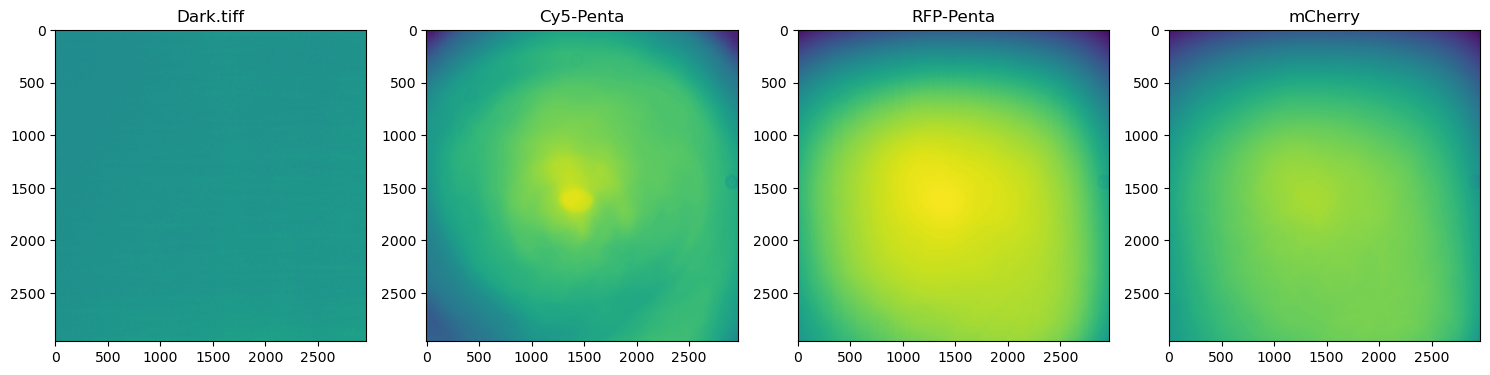

In [24]:
import tifffile
from matplotlib import pyplot as plt

dark_outputpath = (
    # "/home/lag36/scratch/lag36/2024-10-27_Flat-Fields_Daniel/20X_Dark.tiff"
    "/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_Dark.tiff"
)

Cy5_outputpath = (
    "/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_Cy5-Penta_Blue-Dye.tiff"
)

RFP_outputpath = (
    "/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_RFP-Penta_Green-Dye.tiff"
)

Mcherry_outputpath = (
    "/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_mCherry_Green-Dye.tiff"
)

# BF_outputpath = (
#     "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_MicroManager-Phase.tiff"
# )

fflist = [
    dark_outputpath,
    # BF_outputpath,
    Cy5_outputpath,
    # Cy7_outputpath,
    # GFP_outputpath,
    RFP_outputpath,
    Mcherry_outputpath,
]

fig, axs = plt.subplots(figsize=(15, 20), nrows=1, ncols=len(fflist))

for i in range(len(fflist)):
    print(fflist[i])
    axs[i].imshow(tifffile.imread(fflist[i]))
    axs[i].set_title(fflist[i].split('/')[-1].split('_')[1]) #
    # axs[i].set_title(fflist[i].split("/")[-1].split("_")[1])  # CHANGED BY LUIS
plt.tight_layout()


/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_Cy5-Penta_Blue-Dye.tiff
/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_RFP-Penta_Green-Dye.tiff


/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_mCherry_Green-Dye.tiff


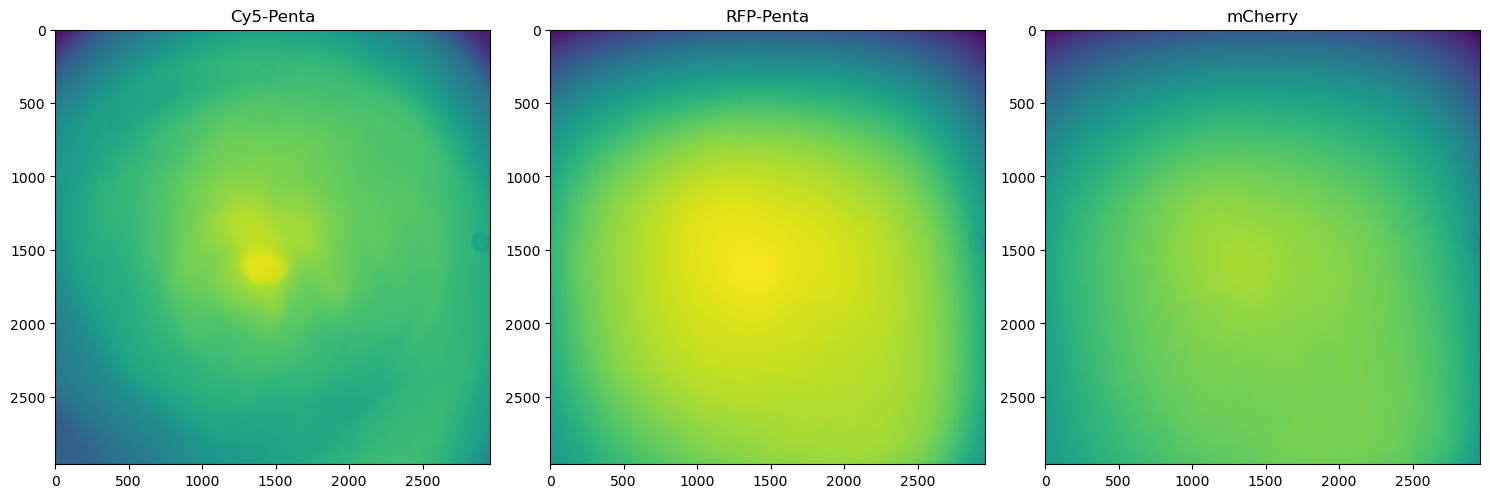

In [7]:
import tifffile
from matplotlib import pyplot as plt

dark_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.tiff"
)

Cy5_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Cy5-Penta.tiff"
)

RFP_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_RFP-Penta.tiff"
)

Mcherry_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_mCherry.tiff"
)

BF_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_MicroManager-Phase.tiff"
)

fflist = [
    dark_outputpath,
    BF_outputpath,
    Cy5_outputpath,
    # Cy7_outputpath,
    # GFP_outputpath,
    RFP_outputpath,
    Mcherry_outputpath,
]

fig, axs = plt.subplots(figsize=(15, 20), nrows=1, ncols=len(fflist))

for i in range(len(fflist)):
    print(fflist[i])
    axs[i].imshow(tifffile.imread(fflist[i]))
    axs[i].set_title(fflist[i].split('/')[-1].split('_')[1]) #
    # axs[i].set_title(fflist[i].split("/")[-1].split("_")[1])  # CHANGED BY LUIS
plt.tight_layout()


# Part 1: Growth/Division

#### Specify Paths

Begin by defining the directory in which all processing will be done, as well as the initial nd2 file we will be <br>processing. This line should be run everytime you open a new python kernel.

The format should be: `headpath = "/path/to/folder"` and `nd2file = "/path/to/file.nd2"`

For example:
```
headpath = "/n/scratch2/de64/2019-05-31_validation_data"
nd2file = "/n/scratch2/de64/2019-05-31_validation_data/Main_Experiment.nd2"
```

Ideally, these files should be placed in a storage location with relatively fast I/O

In [3]:
headpath = "/home/lag36/scratch/lag36/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/Growth_Division/"
nd2file = "/home/lag36/scratch/lag36/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/Experiment.nd2"

## Extract to hdf5 files

In this section, we will be extracting our image data. Currently this notebook only supports `.nd2` format; however <br>there are `.tiff` extractors in the TrenchRipper source files that are being added to `Master.ipynb` soon.

In the abstract, this step will take a single `.nd2` file and split it into a set of `.hdf5` files stored in <br>`headpath/hdf5`. Splitting the file up in this way will facilitate quick procesing in later steps. Each field of <br>view will be split into one or more `.hdf5` files, depending on the number of images per file requested (more on <br>this later). 

To keep track of which output files correspond to which FOVs, as well as to keep track of experiment metadata, the <br>extractor also outputs a `metadata.hdf5` file in the `headpath` folder. The data from this step is accessible in <br>that `metadata.hdf5` file under the `global` key. If you would like to look at this metadata, you may use the <br>`tr.utils.pandas_hdf5_handler` to read from this file. Later steps will add additional metadata under different <br>keys into the `metadata.hdf5` file.

#### Start Dask Workers

First, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [4]:
# dask_controller = tr.trcluster.dask_controller(
#     walltime="1:00:00",
#     local=False,
#     n_workers=100,
#     n_workers_min=20,
#     memory="8GB",
#     working_directory=dask_wd,
# )
# dask_controller.startdask()

In [25]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=500,
    n_workers_min=20,
    memory="3GB",
    working_directory=dask_wd,
)
dask_controller.startdask()

50m
1:00:00


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/node.py:168: ResourceWarning: unclosed <socket.socket fd=100, family=AddressFamily.AF_INET, type=SocketKind.SOCK_STREAM, proto=6, laddr=('0.0.0.0', 0)>
  if retries_left < 1:
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/node.py:182: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 33553 instead
  warnings.warn(


In [26]:
dask_controller.displaydashboard()

After running the above line, you will have a running Dask client. Run the line below and click the link to supervise <br>the computation being administered by the scheduler. 

Don't be alarmed if the screen starts mostly blank, it may take time for your workers to spin up. If you get a 404 <br>error on a cluster, it is likely that your ports are not being forwarded properly. If this occurs, please register <br>the issue on github.

##### Perform Extraction

Now that we have our cluster scheduler spun up, it is time to convert files. This will be handled by the <br>`hdf5_extractor` object. This extractor will pull up each FOV and split it such that each derived `.hdf5` file <br>contains, at maximum, N timepoints of that FOV per file. The image data stored in these files takes the <br>form of `(N,Y,X)` arrays that are accessible using the desired channel name as a key. 

The arguments for this extractor are:

 - **nd2file** : The filepath to the `.nd2` file you intend to extract.
 
 - **headpath** : The folder in which processing is occuring. Should be the same for each step in the pipeline.

 - **tpts_per_file** : The maximum number of timepoints stored in each output `.hdf5` file. Typical values are between 25 <br>and 100.

 - **ignore_fovmetadata** : Used when `.nd2` data is corrupted and does not possess records for stage positions or <br>timepoints. Only set `False` if the extractor throws errors on metadata handling.

 - **nd2reader_override** : Overrides values in metadata recovered using the `nd2reader`. Currently set to <br>`{"z_levels":[],"z_coordinates":[]}` by default to correct a known issue where z coordinates are mistakenly <br>interpreted as a z stack. See the [nd2reader](https://rbnvrw.github.io/nd2reader/) documentation for more info.

In [27]:
EXPERIMENT_START_DELAY_SECONDS = 7*3600
hdf5_extractor = tr.ndextract.hdf5_fov_extractor(
    nd2file,
    headpath,
    tpts_per_file=50,
    ignore_fovmetadata=False,
    nd2reader_override={"z_levels": [], "z_coordinates": []},
    experiment_start_delay_seconds = EXPERIMENT_START_DELAY_SECONDS
)

##### Extraction Parameters

Here, you may set the time interval you want to extract. Useful for cropping data to the period exhibiting the dynamics of interest.

Optionally take notes to add to the `metadata.hdf5` file. Notes may also be taken directly in this notebook.

In [28]:
hdf5_extractor.inter_set_params()

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Python keyword: 'global'; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


interactive(children=(SelectMultiple(description='fov_list', options=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12…

#### List of paths to flat fields

/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_Cy5-Penta_Blue-Dye.tiff

/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_RFP-Penta_Green-Dye.tiff

/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_mCherry_Green-Dye.tiff

/home/lag36/scratch/lag36/2024-12-16_Flat-Fields/20X_Dark.tiff

In [29]:
hdf5_extractor.inter_set_flatfieldpaths()

##### Begin Extraction 

Running the following line will start the extraction process. This may be monitored by examining the `Dask Dashboard` <br> under the link displayed earlier. Once the computation is complete, move to the next line.

This step may take a long time, though it is possible to speed it up using additional workers.

In [30]:
hdf5_extractor.extract(dask_controller)

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Python keyword: 'global'; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Python keyword: 'global'; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)


In [31]:
dask_controller.shutdown()

Done.


## Kymographs

Now that you have extracted your data into a series of `.hdf5` files, we will now perform identification and cropping <br>of the individual trenches/growth channels present in the images. This algorithm assumes that your growth trenches <br>are vertically aligned and that they alternate in their orientation from top to bottom. See the example image for the <br>correct geometry:

![example_image](./resources/example_image.jpg)

The output of this step will be a set of `.hdf5` files stored in `headpath/kymograph`. The image data stored in these <br>files takes the form of `(K,T,Y,X)` arrays where K is the trench index, T is time, and Y,X are the crop dimensions. <br>These arrays are accessible using keys of the form `"[Image Channel]"`. For example, looking up phase channel <br>data of trenches in the topmost row of an image will require the key `"Phase"`

### Test Parameters



#### Typical parameters for mCherry single channel imaging at 20x

- Y Percentile 95
- Y Foreground Percentile 65
- Y Smoothing Kernel 51
- Y Percentile Threshold 0.5
- Minimum Trench Length 50
- Midpoint Distance Tolerance 50
- Y Padding 20
- Trench Length 130
- Orientation Detection Method 1
- Expected Number of Rows (Manual Orientation Detection) 10
- Alternate Orientation True
- Alternate Orientation Over Rows? False
- Use Median Drift? True
- Consensus Orientations [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
- Consensus Midpoints [168.0, 411.5, 773.0, 1014.5, 1373.5, 1615.0, 1975.5, 2215.0, 2576.5, 2817.0]
- X Percentile 85
- X Background Kernel 51
- X Smoothing Kernel 5
- Otsu Threshold Scaling 0.0
- Minimum X Threshold 300
- Trench Width 20
- Trench Presence Threshold 0.8
- All Channels ['mCherry']
- Filter Channel None
- Invert False

##### Initialize the interactive kymograph class

As a first step, initialize the `tr.interactive.kymograph_interactive` class that will be help us choose the <br>parameters we will use to generate kymographs. 

In [20]:
interactive_kymograph = tr.kymograph_interactive(headpath)

/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


In [11]:
viewer = tr.hdf5_viewer(headpath,persist_data=False)

/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


##### Examine Images

Here you can manually inspect images before beginning parameter tuning.

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
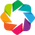

BokehModel(combine_events=True, render_bundle={'docs_json': {'8653bc1f-0872-4663-b1de-80cf5cb7291a': {'version…

In [12]:
viewer.view(width=1200)

You will now want to select a few test FOVs to try out parameters on, the channel you want to detect trenches on, and <br>the time interval on which you will perform your processing.

The arguments for this step are:

- **seg_channel (string)** : The channel name that you would like to segment on.

- **invert (list)** : Whether or not you want to invert the image before detecting trenches. By default, it is assumed that <br>the trenches have a high pixel intensity relative to the background. This should be the case for Phase Contrast and <br>Fluorescence Imageing, but may not be the case for Brightfield Imaging, in which case you will want to invert the image.

- **fov_list (list)** : List of integers corresponding to the FOVs that you wish to make test kymographs of.

- **t_subsample_step (int)** : Step size to be used for subsampling input files in time, recommend that subsampling results in <br>between 5 and 10 timepoints for quick processing.

Hit the "Run Interact" button to lock in your parameters. The button will become transparent briefly and become solid again <br>when processing is complete. After that has occured, move on to the next step. 

In [21]:
interactive_kymograph.import_hdf5_interactive()

interactive(children=(Dropdown(description='seg_channel', options=('mCherry',), value='mCherry'), Dropdown(des…

##### Tune "trench-row" detection hyperparameters

The kymograph code begins by detecting the positions of trench rows in the image as follows:

1. Reducing each 2D image to a 1D signal along the y-axis by computing the qth percentile of the data along the x-axis
2. Smooth this signal using a median kernel
3. Normalize the signal by linearly scaling 0. and 1. to the minimum and maximum, respectively
4. Use a set threshold to determine the trench row poisitons

The arguments for this step are:

 - **y_percentile (int)** : Percentile to use for step 1.

 - **smoothing_kernel_y_dim_0 (int)** : Median kernel size to use for step 2.

 - **y_percentile_threshold (float)** : Threshold to use in step 4.

Running the following widget will display the smoothed 1-D signal for each of your timepoints. In addition, the threshold <br>value for each fov will be displayed as a red line.

In [ ]:
interactive_kymograph.preview_y_precentiles_interactive()

interactive(children=(IntSlider(value=99, description='y_percentile'), IntSlider(value=80, description='y_fore…

##### Tune "trench-row" cropping hyperparameters

Next, we will use the detected rows to perform cropping of the input image in the y-dimension:

1. Determine edges of trench rows based on threshold mask.
2. Filter out rows that are too small.
3. Use the remaining rows to compute the drift in y in each image.
4. Apply the drift to the initally detected rows to get rows in all timepoints.
5. Perform cropping using the "end" of the row as reference (the end referring to the part of the trench farthest from <br>the feeding channel).

Step 5 performs a simple algorithm to determine the orientation of each trench:

```
row_orientations = [] # A list of row orientations, starting from the topmost row
if the number of detected rows == 'Number of Rows': 
    row_orientations.append('Orientation')
elif the number of detected rows < 'Number of Rows':
    row_orientations.append('Orientation when < expected rows')
for row in rows:
    if row_orientations[-1] == downward:
        row_orientations.append(upward)
    elif row_orientations[-1] == upward:
        row_orientations.append(downward)
```

Additionally, if the device tranches face a single direction, alternation of row orientation may be turned off by setting the<br> `Alternate Orientation?` argument to False. The `Use Median Drift?` argument, when set to True, will use the<br> median drift in y across all FOVs for drift correction, instead of doing drift correction independently for all FOVs. <br>This can be useful if there are a large fraction of FOVs which are failing drift correction. Note that `Use Median Drift?` <br>sets this behavior for both y and x drift correction.

The arguments for this step are:

 - **y_min_edge_dist (int)** : Minimum row length necessary for detection (filters out small detected objects).

 - **padding_y (int)** : Padding to add to the end of trench row when cropping in the y-dimension.

 - **trench_len_y (int)** : Length from the end of each trench row to the feeding channel side of the crop.

 - **Number of Rows (int)** : The number of rows to expect in your image. For instance, two in the example image.
 
 - **Alternate Orientation? (bool)** : Whether or not to alternate the orientation of consecutive rows.

 - **Orientation (int)** : The orientation of the top-most row where 0 corresponds to a trench with a downward-oriented trench <br>opening and 1 corresponds to a trench with an upward-oriented trench opening.

 - **Orientation when < expected rows(int)** : The orientation of the top-most row when the number of detected rows is less than <br>expected. Useful if your trenches drift out of your image in some FOVs.
 
 - **Use Median Drift? (bool)** : Whether to use the median detected drift across all FOVs, instead of the drift detected in each FOV individually.

 - **images_per_row(int)** : How many images to output per row for this widget.

Running the following widget will display y-cropped images for each fov and timepoint.

In [ ]:
interactive_kymograph.preview_y_precentiles_consensus_interactive()

interactive(children=(IntSlider(value=50, description='n_fovs', step=5), Dropdown(description='Y Consensus Ena…

In [ ]:
interactive_kymograph.preview_y_crop_interactive()

interactive(children=(IntSlider(value=50, description='y_min_edge_dist', max=1000, min=5, step=5), IntSlider(v…

##### Tune trench detection hyperparameters

Next, we will detect the positions of trenchs in the y-cropped images as follows:

1. Reducing each 2D image to a 1D signal along the x-axis by computing the qth percentile of the data along the y-axis.
2. Determine the signal background by smoothing this signal using a large median kernel.
3. Subtract the background signal.
4. Smooth the resultant signal using a median kernel.
5. Use an [otsu threhsold](https://imagej.net/Auto_Threshold#Otsu) to determine the trench midpoint poisitons.

After this, x-dimension drift correction of our detected midpoints will be performed as follows:

6. Begin at t=1
7. For $m \in \{midpoints(t)\}$ assign $n \in \{midpoints(t-1)\}$ to m if n is the closest midpoint to m at time $t-1$,<br>
points that are not the closest midpoint to any midpoints in m will not be mapped.
8. Compute the translation of each midpoint at time.
9. Take the average of this value as the x-dimension drift from time t-1 to t.

The arguments for this step are:

 - **t (int)** : Timepoint to examine the percentiles and threshold in.

 - **x_percentile (int)** : Percentile to use for step 1.

 - **background_kernel_x (int)** : Median kernel size to use for step 2.

 - **smoothing_kernel_x (int)** : Median kernel size to use for step 4.

 - **otsu_scaling (float)** : Scaling factor to apply to the threshold determined by Otsu's method.

Running the following widget will display the smoothed 1-D signal for each of your timepoints. In addition, the threshold <br>value for each fov will be displayed as a red line. In addition, it will display the detected midpoints for each of your timepoints. <br>If there is too much sparsity, or discontinuity, your drift correction will not be accurate.

In [25]:
# # read from a binary pickle file
# import pickle
# with open('/home/lag36/scratch/lag36/2024-10-31_lLAG8_MBM_Run-2/Growth_Division/kymograph.par', 'rb') as f:
#     kymograph_data = pickle.load(f)
# kymograph_data

In [27]:
interactive_kymograph.preview_x_percentiles_interactive()

interactive(children=(IntSlider(value=0, description='t', max=3), IntSlider(value=85, description='x_percentil…

##### Tune trench cropping hyperparameters

Trench cropping simply uses the drift-corrected midpoints as a reference and crops out some fixed length around them <br>
to produce an output kymograph. **Note that the current implementation does not allow trench crops to overlap**. If your<br>
trench crops do overlap, the error will not be caught here, but will cause issues later in the pipeline. As such, try <br>
to crop your trenches as closely as possible. This issue will be fixed in a later update.

The arguments for this step are:

 - **trench_width_x (int)** : Trench width to use for cropping.

 - **trench_present_thr (float)** : Trenches that appear in less than this percent of FOVs will be eliminated from the dataset.<br>
If not removed, missing positions will be inferred from the image drift.

 - **Use Median Drift? (bool)** : Whether to use the median detected drift across all FOVs, instead of the drift detected in each FOV individually.


Running the following widget will display a random kymograph for each row in each fov and will also produce midpoint plots <br>showing retained midpoints

In [28]:
interactive_kymograph.preview_kymographs_interactive()

interactive(children=(IntSlider(value=30, description='trench_width_x', max=1000, min=2, step=2), FloatSlider(…

##### Export and save hyperparameters

Run the following line to register and display the parameters you have selected for kymograph creation.

In [29]:
interactive_kymograph.process_results()

Y Percentile 95
Y Foreground Percentile 65
Y Smoothing Kernel 51
Y Percentile Threshold 0.5
Minimum Trench Length 50
Midpoint Distance Tolerance 50
Y Padding 20
Trench Length 150
Orientation Detection Method 1
Expected Number of Rows (Manual Orientation Detection) 10
Alternate Orientation True
Alternate Orientation Over Rows? False
Use Median Drift? False
Consensus Orientations [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
Consensus Midpoints [196.0, 428.5, 797.5, 1029.0, 1399.0, 1630.5, 2000.5, 2231.5, 2602.5, 2833.0]
X Percentile 85
X Background Kernel 51
X Smoothing Kernel 5
Otsu Threshold Scaling 0.0
Minimum X Threshold 100
Trench Width 16
Trench Presence Threshold 1.0
All Channels ['mCherry']
Filter Channel None
Invert False


If you are satisfied with the above parameters, run the following line to write these parameters to disk at `headpath/kymograph.par`<br>
This file will be used to perform kymograph creation in the next section.

In [31]:
interactive_kymograph.write_param_file()

### Generate Kymograph

##### Start Dask Workers

Again, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2 for kymograph creation. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [32]:
dask_controller = tr.trcluster.dask_controller(
    walltime="3:00:00",
    local=False,
    n_workers=200,#300,
    n_workers_min=20,
    memory="4GB",#"4GB is fine",
    working_directory=dask_wd,
)
dask_controller.startdask()

dask_controller.displaydashboard()

170m
3:00:00


After running the above line, you will have a running Dask client. Run the line below and click the link to supervise <br>the computation being administered by the scheduler. 

Don't be alarmed if the screen starts mostly blank, it may take time for your workers to spin up. If you get a 404 <br>error on a cluster, it is likely that your ports are not being forwarded properly. If this occurs, please register <br>the issue on github.

##### Perform Kymograph Cropping

Now that we have our cluster scheduler spun up, we will extract kymographs using the parameters stored in `headpath/kymograph.par`. <br>
This will be handled by the `kymograph_cluster` object. This will detect trenches in all of the files present in `headpath/hdf5` that <br>
you created in the first step. It will then crop these trenches and place the crops in a series of `.hdf5` files in `headpath/kymograph`. <br>
These files will store image data in the form of `(K,T,Y,X)` arrays where K is the trench index, T is time and Y,X are the image dimensions <br>
of the crop.

The arguments for this step are:

 - **headpath** : The folder in which processing is occuring. Should be the same for each step in the pipeline.

 - **trenches_per_file** : The maximum number of trenches stored in each output `.hdf5` file. Typical values are between 25 <br>and 100.

 - **paramfile** : Set to true if you want to use parameters from `headpath/kymograph.par` Otherwise, you will have to specify <br>
 parameters as direct arguments to `kymograph_cluster`.

In [33]:
kymoclust = tr.kymograph.kymograph_cluster(
    headpath=headpath, paramfile=True
)

##### Begin Kymograph Cropping 

Running the following line will start the cropping process. This may be monitored by examining the `Dask Dashboard` <br>
under the link displayed earlier. Once the computation is complete, move to the next line.

**Do not move on until all tasks are displayed as 'in memory' in Dask.**

In [35]:
kymoclust.generate_kymographs(dask_controller)
# 4GB is good with 73 timepoints (13 hours)

/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:6150: UserWarning: 
You did not provide metadata, so Dask is running your function on a small dataset to guess output types. It is possible that Dask will guess incorrectly.
To provide an explicit output types or to silence this message, please provide the `meta=` keyword, as described in the map or apply function that you are using.
  Before: .apply(func)
  After:  .apply(func, meta=(None, 'int64'))

  warnings.warn(meta_warning(meta))
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 9.63 MiB.
This may cause some slowdown.
Consider scattering

In [36]:
ff = tr.focus_filter(headpath)

In [37]:
ff.choose_filter_channel_inter()

interactive(children=(Dropdown(description='channel', options=(None,), value=None), Button(description='Run In…

In [38]:
ff.plot_histograms(intensity_range=(0,1500))

TypeError: unsupported operand type(s) for +: 'NoneType' and 'str'

In [39]:
ff.plot_focus_threshold_inter()

No Channel Selected


In [40]:
ff.write_param_file()

In [41]:
lane_overlay_handle = tr.lane_overlay(headpath,persist_data=True)

/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
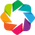

In [42]:
overlay = lane_overlay_handle.view_overlay(size=2500,vmin=0,vmax=4000)

In [44]:
lane_overlay_handle.save_rows()

Eliminated Rows: []


##### Post-process Images

After the above step, kymographs will have been created for each `.hdf5` input file. They will now need to be reorganized <br>
into a new set of files such that each file has, at most, `trenches_per_file` trenches in each file.

**Do not move on until all tasks are displayed as 'in memory' in Dask.**

In [45]:
dask_controller.reset_worker_memory()

Done.


In [46]:
kymoclust.post_process(dask_controller,trench_timepoints_per_file=10000)

Eliminating selected rows...


/home/lag36/gutiloluis/TrenchRipper/trenchripper/kymograph.py:1553: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  fov_to_rows_series = outputdf.groupby("fov")["row"].apply(lambda x: sorted(list(set(x)))).compute().sort_index()


Number of timepoints per trench: 73
Number of trenches per file: 136


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 692.15 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 692.15 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:7234: FutureWarning: Meta is not valid, `map_partitions` and `map_overlap` expects output to be a pandas object. Try passing a pandas object as meta or a dict or tuple representing the (name, dtype) of the columns. In the future the meta you passed will not work.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:6150: UserWarning: 
You did not provide m

In [47]:
dask_controller.shutdown()

Done.


2025-05-12 16:01:49,386 - distributed.deploy.adaptive_core - INFO - Adaptive stop


##### Check kymograph statistics

Run the next line to display some statistics from kymograph creation. The outputs are:

 - **fovs processed** : The number of FOVs successfully processed out of the total number of FOVs
 - **rows processed** : The number of rows of trenches processed out of the total number of rows
 - **trenches processed** : The number of trenches successfully processed
 - **row/fov** : The average number of rows successfully processed per FOV
 - **trenches/fov** : The average number of trenches successfully processed per FOV
 - **failed fovs** : A list of failed FOVs. Spot check these FOVs in the viewer to determine potential problems

In [48]:
kymoclust.kymo_report()

fovs processed: 629/629
rows processed: 6226
trenches processed: 621355
row/fov: 9.89825119236884
trenches/fov: 987.845786963434
failed fovs: []


In [ ]:
kymoclust.kymo_report() # When focus-filtered

fovs processed: 624/629
rows processed: 6176
trenches processed: 594560
row/fov: 9.897435897435898
trenches/fov: 952.8205128205128
failed fovs: [174, 146, 562, 84, 378]


In [49]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

def plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "kymograph", prefix = "kymograph", cmap = "gray"):
    file_path = headpath + subfolder + "/" + prefix+"_" + str(kymo_index) + ".hdf5"
    # print(file_path)
    with h5py.File(file_path, "r") as infile:
        # print(infile['mCherry'].shape)
        # indices = list(range(0, 1, 1))

        for ch in channels:
            img = infile[ch][trench_index][indices[0]]
            for ind in indices[1:]:
                img_ind = infile[ch][trench_index][ind]
                img = np.concatenate((img, img_ind), axis=1)
            _= plt.figure()
            _ = plt.imshow(img, cmap=cmap, aspect=1)
            # Annotate kymo and trench index
            _= plt.text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
            _=plt.show()
            _=plt.close()

indices = np.arange(0, 67)
# Create a function to update the plot
def update_plot(trench_index, kymo_index):
    # y = np.sin(frequency * x)
    _ = plt.clf()  # Clear the previous plot
    channels = ["mCherry"]
    plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "kymograph", prefix = "kymograph", cmap='gray')
    _ = plt.show()
    # channels = ["data"]
    # plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "fluorsegmentation", prefix="segmentation", cmap="jet")
    # _ = plt.show()

# Create an interactive slider widget
trench_index_slider = widgets.IntSlider(min=0, max=149, step=1, value=0)
kymo_index_slider = widgets.IntSlider(min=0, max=500, step=1, value=0)

In [50]:
# Use the interact function to connect the slider to the update_plot function
interact(update_plot, trench_index=trench_index_slider, kymo_index=kymo_index_slider)# kymo_index=kymo_index_slider)

interactive(children=(IntSlider(value=0, description='trench_index', max=149), IntSlider(value=0, description=…

<function __main__.update_plot(trench_index, kymo_index)>

In [104]:
dask_controller.shutdown()

Done.


2025-04-25 11:41:47,161 - distributed.deploy.adaptive_core - INFO - Adaptive stop


[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66]


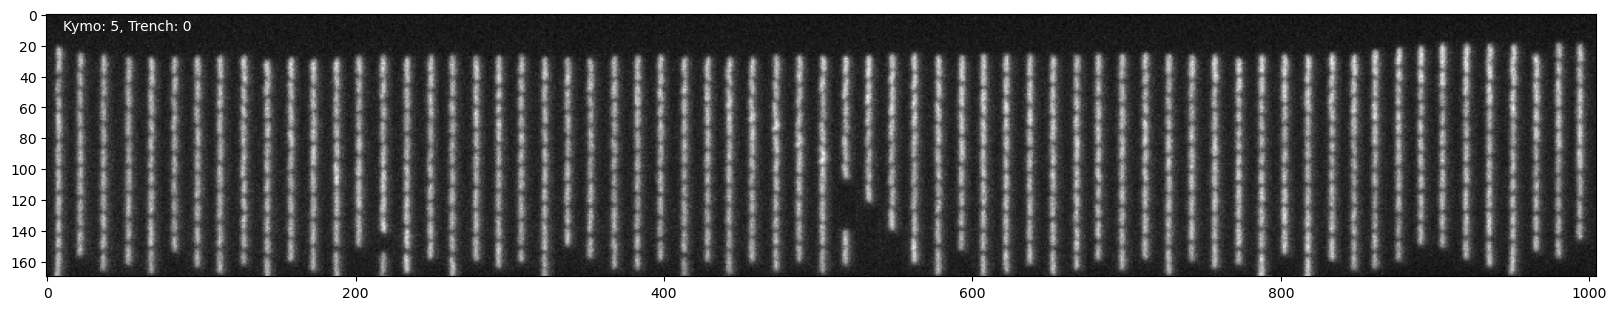

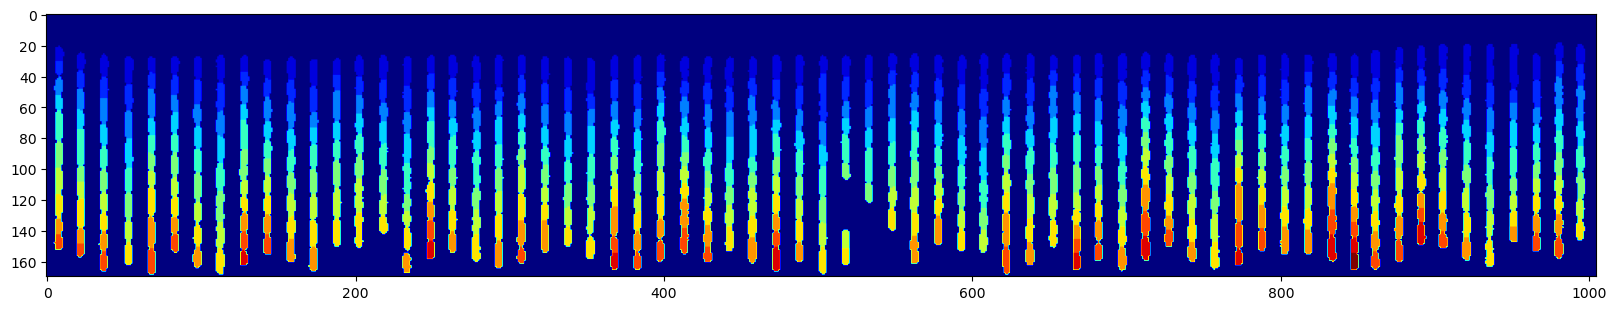

In [109]:
### QC segmentation
import h5py
import matplotlib.pyplot as plt
import numpy as np

indices = np.arange(0, 67)
print(indices)
channels = ["mCherry"]
trench_index = 0 # BAD: 1 (k30), GOOD: k30-20
kymo_index = 5
with h5py.File(
    "/home/lag36/scratch/lag36/2024-10-31_lLAG8_MBM_Run-2/Growth_Division/kymograph/kymograph_"
    + str(kymo_index)
    + ".hdf5",
    "r",
) as infile:
    # indices = list(range(0, 1, 1))

    for ch in channels:
        img = infile[ch][trench_index][indices[0]]
        for ind in indices[1:]:
            img_ind = infile[ch][trench_index][ind]
            img = np.concatenate((img, img_ind), axis=1)
        plt.figure()
        plt.imshow(img, cmap="gray", aspect=1)
        # Annotate kymo and trench index
        plt.text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
        plt.show()
        plt.close()

channels = ["data"]
# trench_index = 110  #BAD: 1 (k30), GOOD: k30-20
with h5py.File(
    "/home/lag36/scratch/lag36/2024-10-31_lLAG8_MBM_Run-2/Growth_Division/fluorsegmentation/segmentation_"
    + str(kymo_index)
    + ".hdf5",
    "r",
) as infile:
    # indices = list(range(0, 1, 1))

    for ch in channels:
        img = infile[ch][trench_index][indices[0]]
        for ind in indices[1:]:
            img_ind = infile[ch][trench_index][ind]
            img = np.concatenate((img, img_ind), axis=1)
        plt.figure()#figsize=(3, 6))
        plt.imshow(img, cmap="jet", aspect=1)
        plt.show()
        plt.close()

In [96]:
dask_controller.shutdown()

2025-04-29 16:11:58,226 - distributed.deploy.adaptive_core - INFO - Adaptive stop


Done.


## Fluorescence Segmentation

Now that you have copped your data into kymographs, we will now perform segmentation/cell detection <br>
on your kymographs. Currently, this pipeline only supports segmentation of fluorescence images; however, <br>
segmentation of transmitted light imaging techniques is in development.

The output of this step will be a set of `segmentation_[File #].hdf5` files stored in `headpath/fluorsegmentation`.<br>
The image data stored in these files takes the exact same form as the kymograph data, `(K,T,Y,X)` arrays <br>
where K is the trench index, T is time, and Y,X are the crop dimensions. These arrays are accessible using <br>
keys of the form `"[Trench Row Number]"`.

Since no metadata is generated by this step, it is possible to use another segmentation algorithm on the kymograph <br>
data. The output of segmentation must be split into `segmentation_[File #].hdf5` files, where `[File #]` agrees with the<br>
corresponding `kymograph_[File #].hdf5` file. Additionally, the `(K,T,Y,X)` arrays must be of the same shape as the <br>
kymograph arrays and accessible at the corresponding `"[Trench Row Number]"` key. These files must be placed into <br>
their own folder at `headpath/foldername`. This folder may then be used in later steps.

### Test Parameters

#### Typical parameters for mCherry single channel imaging at 20x

- Extra Mask Path: None
- 8 Bit Maximum: 6000
- Scale Fluorescence? False
- Scaling Percentile: 90
- Image Scaling Factor: 1.0
- Gaussian Kernel Sigma: 1.0
- Local Threshold Method: otsu
- Background Threshold Method: triangle
- Global Threshold: 18
- Local Window Size: 11
- Otsu Scaling: 0.9999999999999999
- Niblack K: 0.2
- Background Threshold Scaling: 1.0
- Minimum Object Size: 20
- Hessian Blur Sigma: 1.75
- Hessian Rolling Ball Size: 20
- Hessian Local Threshold Method: niblack
- Hessian Otsu Scaling: 0.9999999999999999
- Hessian Niblack K: 0.05
- Hessian Local Window Size: 7
- Distance Threshold: 1
- Border Buffer: 1
- Horizontal Border Only: False
- Segmentation Channel: mCherry

##### Initialize the interactive segmentation class

As a first step, initialize the `tr.fluo_segmentation_interactive` class that will be handling all steps of generating a segmentation. 

In [51]:
interactive_segmentation = tr.fluo_segmentation_interactive(headpath)

/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


##### Choose channel to segment on

In [52]:
interactive_segmentation.choose_seg_channel_inter()

interactive(children=(Dropdown(description='seg_channel', options=('mCherry',), value='mCherry'), Dropdown(des…

#### Import data

Fill in 

You will need to tune the following `args` and `kwargs` (in order):

**fov_idx (int)** :

**n_trenches (int)** :

**t_range (tuple)** :

**t_subsample_step (int)** :

In [53]:
interactive_segmentation.import_array_inter()

interactive(children=(IntText(value=12, description='Number of trenches:'), IntRangeSlider(value=(0, 72), desc…

##### Process data

In [ ]:
interactive_segmentation.plot_processed_inter()

interactive(children=(IntSlider(value=1000, description='8-bit Maximum:', max=65535, step=250), Dropdown(descr…

#### Determine Cell Mask Envelope

Fill in.

You will need to tune the following `args` and `kwargs` (in order):

**cell_mask_method (str)** : Thresholding method, can be a local or global Otsu threshold.

**cell_otsu_scaling (float)** : Scaling factor applied to determined threshold.

**local_otsu_r (int)** : Radius of thresholding kernel used in the local otsu thresholding.

In [55]:
interactive_segmentation.plot_cell_mask_inter()

interactive(children=(Dropdown(description='local_thr', options=('otsu', 'niblack', 'none'), value='otsu'), Dr…

In [ ]:
interactive_segmentation.plot_eig_mask_inter()

interactive(children=(FloatSlider(value=2.0, description='Hessian Blur Sigma:', max=5.0, step=0.25), IntSlider…

In [57]:
interactive_segmentation.plot_dist_mask_inter()

interactive(children=(IntSlider(value=2, description='Distance Threshold:', max=20), Button(description='Run I…

In [ ]:
# import pickle as pkl
# with open('/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Growth_Division/fluorescent_segmentation.par', 'rb') as f:
#     x = pkl.load(f)
# x

In [58]:
interactive_segmentation.plot_marker_mask_inter()

interactive(children=(FloatSlider(value=2.0, description='Hessian Blur Sigma:', max=5.0, step=0.25), IntSlider…

In [59]:
interactive_segmentation.process_results()

Extra Mask Path: None
8 Bit Maximum: 1500
Scale Fluorescence? False
Scaling Percentile: 90
Image Scaling Factor: 1.0
Gaussian Kernel Sigma: 1.0
Local Threshold Method: otsu
Background Threshold Method: triangle
Global Threshold: 22
Local Window Size: 9
Otsu Scaling: 0.9999999999999999
Niblack K: 0.2
Background Threshold Scaling: 1.0
Minimum Object Size: 14
Hessian Blur Sigma: 2.0
Hessian Rolling Ball Size: 20
Hessian Local Threshold Method: niblack
Hessian Otsu Scaling: 0.9999999999999999
Hessian Niblack K: 0.15
Hessian Local Window Size: 7
Distance Threshold: 1
Border Buffer: 0
Horizontal Border Only: False
Segmentation Channel: mCherry


In [60]:
interactive_segmentation.write_param_file()

In [ ]:
dask_controller.shutdown()

### Generate Segmentation

#### Start Dask Workers

In [61]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=500,
    n_workers_min=20,
    memory="2GB",
    working_directory=dask_wd,
)
dask_controller.startdask()

50m
1:00:00


In [62]:
dask_controller.displaydashboard()

In [63]:
segment = tr.segment.fluo_segmentation_cluster(headpath, paramfile=True)

In [64]:
segment.dask_segment(dask_controller)

Done.


In [65]:
print(1)

1


In [66]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

def plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "kymograph", prefix = "kymograph", cmap = "gray"):
    file_path = headpath + subfolder + "/" + prefix+"_" + str(kymo_index) + ".hdf5"
    # print(file_path)
    with h5py.File(file_path, "r") as infile:
        # print(infile['mCherry'].shape)
        # indices = list(range(0, 1, 1))

        for ch in channels:
            img = infile[ch][trench_index][indices[0]]
            for ind in indices[1:]:
                img_ind = infile[ch][trench_index][ind]
                img = np.concatenate((img, img_ind), axis=1)
            _= plt.figure()
            _ = plt.imshow(img, cmap=cmap, aspect=1)
            # Annotate kymo and trench index
            _= plt.text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
            _=plt.show()
            _=plt.close()

indices = np.arange(0, 67)
# Create a function to update the plot
def update_plot(trench_index, kymo_index):
    # y = np.sin(frequency * x)
    _ = plt.clf()  # Clear the previous plot
    channels = ["mCherry"]
    plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "kymograph", prefix = "kymograph", cmap='gray')
    channels = ['data']
    plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "fluorsegmentation", prefix = "segmentation", cmap='jet')
    _ = plt.show()
    # channels = ["data"]
    # plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "fluorsegmentation", prefix="segmentation", cmap="jet")
    # _ = plt.show()

# Create an interactive slider widget
trench_index_slider = widgets.IntSlider(min=0, max=149, step=1, value=0)
kymo_index_slider = widgets.IntSlider(min=0, max=500, step=1, value=0)

In [67]:
# Use the interact function to connect the slider to the update_plot function
interact(update_plot, trench_index=trench_index_slider, kymo_index=kymo_index_slider)# kymo_index=kymo_index_slider)

interactive(children=(IntSlider(value=0, description='trench_index', max=149), IntSlider(value=0, description=…

<function __main__.update_plot(trench_index, kymo_index)>

#### Stop Dask Workers

In [68]:
dask_controller.shutdown()

Done.


2025-05-12 16:47:30,478 - distributed.deploy.adaptive_core - INFO - Adaptive stop


## Lineage Tracing

#### Typical parameters for mCherry single channel imaging at 20x

- Channels: ['mCherry']
- Closest N Objects to Consider: 2
- Mean Size Increase: 0.08
- Standard Deviation of Size Increase: 0.03
- Mean Position Increase: 0.1
- Standard Deviation of Position Increase: 0.05
- Cell Position Weight: 1.0
- Cell Size Weight: 1.0
- Cell Merging Weight: 0.0

### Test Parameters

In [94]:
import pandas as pd

In [16]:
score_function = tr.tracking.scorefn(
    headpath,
    "fluorsegmentation",
    size_attr='axis_major_length',
    u_size=0.08,
    sig_size=0.03,
    u_pos=0.1,
    sig_pos=0.05,
    w_merge=0.,
)

In [17]:
score_function.interactive_scorefn()

interactive(children=(IntSlider(value=0, description='trenchid', max=594559), IntRangeSlider(value=(0, 72), co…

In [18]:
Tracking_Solver = tr.tracking.tracking_solver(
    headpath, "fluorsegmentation", ScoreFn=score_function, edge_limit=2,
)
data, orientation = score_function.output.result

/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


In [ ]:
Tracking_Solver.interactive_tracking(data, orientation)

interactive(children=(SelectMultiple(description='intensity_channel_list', options=('mCherry',), value=()), In…

In [20]:
Tracking_Solver.save_params()

Channels: ['mCherry']
Closest N Objects to Consider: 2
Size Measurement: axis_major_length
Mean Size Increase: 0.08
Standard Deviation of Size Increase: 0.02
Mean Position Increase: 0.1
Standard Deviation of Position Increase: 0.05
Cell Position Weight: 1.0
Cell Size Weight: 1.0
Cell Merging Weight: 0.0


### Generate Lineage Traces

In [71]:
# dask_controller = tr.trcluster.dask_controller(
#     walltime="1:00:00",
#     local=False,
#     n_workers=300,
#     n_workers_min=20,
#     memory="1GB",
#     death_timeout=60.,
#     working_directory=dask_wd,
# )
# dask_controller.startdask()
dask_controller = tr.trcluster.dask_controller(
    walltime="2:00:00",
    local=False,
    n_workers=200, #200,#500,
    n_workers_min=50,
    memory="3GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

110m
2:00:00


In [70]:
dask_controller.shutdown()

Done.


2025-05-12 16:49:11,801 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [72]:
# Tracking_Solver = tr.tracking.tracking_solver(
#     headpath, "fluorsegmentation", paramfile=True, volume_estimation=True, props_list=['area','major_axis_length','minor_axis_length'],
#     props_to_unpack={},pixel_scaling_factors={'area': 2, 'major_axis_length': 1,'minor_axis_length': 1},intensity_props_list=['mean_intensity'] 
# )

Tracking_Solver = tr.tracking.tracking_solver(
    headpath, 
    "fluorsegmentation", 
    paramfile=True, 
    size_estimation=True,
    size_estimation_method='Perimeter/Area',
    props_list=['area'], 
    props_to_unpack={},
    pixel_scaling_factors={'area': 2},
    intensity_props_list=['mean_intensity'] 
)

/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


In [73]:
headpath

'/home/lag36/scratch/lag36/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/Growth_Division/'

In [76]:
Tracking_Solver.compute_all_lineages(dask_controller,entries_per_partition = 100000, overwrite=False)

Kymograph files per partition: 11
Done.
Done.
# Trenches Processed / # Trenches = 595364/621355


In [ ]:
# Tracking_Solver.compute_all_lineages(dask_controller,entries_per_partition = 100000, overwrite=True)

Kymograph files per partition: 11
Done.
Done.
# Trenches Processed / # Trenches = 542253/594560


In [77]:
print(1)

1


In [4]:
headpath

'/home/lag36/scratch/lag36/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/Growth_Division/'

In [8]:
import dask.dataframe as dd

In [78]:
kymograph_path = headpath+'kymograph/metadata'
kymo_df = dd.read_parquet(kymograph_path,calculate_divisions=True)

In [79]:
# Read lineage df
lineage_df = dd.read_parquet(headpath+'lineage/output')


In [14]:
lineage_df_inds = lineage_df['Kymograph FOV Parquet Index'].unique().compute()

In [81]:
kymo_df_inds = kymo_df.index.unique()

In [82]:
840000 in kymo_df_inds

/tmp/ipykernel_15420/1241238456.py:1: FutureWarning: Using the ``in`` operator to test for membership in Series is deprecated. To test for membership in the index use ``(s.index == key).any()``. Similarly to test for membership in the values use ``(s == key).any()``
  840000 in kymo_df_inds


True

In [16]:
840000 in lineage_df_inds

True

In [83]:
dask_controller.shutdown()

Done.


2025-05-12 19:15:25,008 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [18]:
kymo_df.head()

,fov,row,trench,timepoints,time (s),lane orientation,y (local),x (local),y (global),x (global),mCherry Focus Score,mCherry Mean Intensity,Global Row,File Index,File Trench Index,File Parquet Index,trenchid,Trenchid Timepoint Index
FOV Parquet Index,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0.612847,bottom,28.863478,4.562976,15734.963478,6437.162976,0.427664,500.224314,0,0,0,0,0,0
1,0,0,0,1,609.502510,bottom,28.863478,4.138513,15735.063478,6436.638513,0.391888,500.541176,0,0,0,1,0,1
2,0,0,0,2,1209.446181,bottom,29.287941,4.138513,15735.187941,6436.738513,0.419641,499.467059,0,0,0,2,0,2
3,0,0,0,3,1809.413214,bottom,29.075710,4.138513,15735.275710,6436.638513,0.407144,520.552941,0,0,0,3,0,3
4,0,0,0,4,2409.442248,bottom,29.500173,4.138513,15735.300173,6436.638513,0.440220,510.066667,0,0,0,4,0,4


In [17]:
840000 in kymo_df.index

/tmp/ipykernel_15420/2868634178.py:1: FutureWarning: Using the ``in`` operator to test for membership in Series is deprecated. To test for membership in the index use ``(s.index == key).any()``. Similarly to test for membership in the values use ``(s == key).any()``
  840000 in kymo_df.index


False

In [11]:
dask_controller.shutdown()

Done.


2025-05-12 14:50:54,121 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [11]:
print(1)

1


# Part 2: Barcodes

#### Specify Paths

Begin by defining the directory in which all processing will be done, as well as the initial nd2 file we will be <br>processing. This line should be run everytime you open a new python kernel.

The format should be: `headpath = "/path/to/folder"` and `nd2file = "/path/to/file.nd2"`

For example:
```
headpath = "/n/scratch2/de64/2019-05-31_validation_data"
nd2file = "/n/scratch2/de64/2019-05-31_validation_data/Main_Experiment.nd2"
```

Ideally, these files should be placed in a storage location with relatively fast I/O

In [5]:
headpath = "/home/lag36/scratch/lag36/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/Barcodes/"
hdf5inputpath = "/home/lag36/scratch/lag36/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/run/"

## Extract to hdf5 files

In this section, we will be extracting our image data. Currently this notebook only supports `.nd2` format; however <br>there are `.tiff` extractors in the TrenchRipper source files that are being added to `Master.ipynb` soon.

In the abstract, this step will take a single `.nd2` file and split it into a set of `.hdf5` files stored in <br>`headpath/hdf5`. Splitting the file up in this way will facilitate quick procesing in later steps. Each field of <br>view will be split into one or more `.hdf5` files, depending on the number of images per file requested (more on <br>this later). 

To keep track of which output files correspond to which FOVs, as well as to keep track of experiment metadata, the <br>extractor also outputs a `metadata.hdf5` file in the `headpath` folder. The data from this step is accessible in <br>that `metadata.hdf5` file under the `global` key. If you would like to look at this metadata, you may use the <br>`tr.utils.pandas_hdf5_handler` to read from this file. Later steps will add additional metadata under different <br>keys into the `metadata.hdf5` file.

#### Start Dask Workers

First, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [5]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=200,
    n_workers_min=20,
    memory="3GB",#3GB next time
    working_directory=dask_wd,
)
dask_controller.startdask()

50m
1:00:00


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/node.py:168: ResourceWarning: unclosed <socket.socket fd=76, family=AddressFamily.AF_INET, type=SocketKind.SOCK_STREAM, proto=6, laddr=('0.0.0.0', 0)>
  if retries_left < 1:
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/node.py:182: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 46830 instead
  warnings.warn(


In [6]:
dask_controller.daskclient

Connection method: Cluster object,Cluster type: dask_jobqueue.SLURMCluster
Dashboard: http://10.120.16.163:46830/status,
Dashboard: http://10.120.16.163:46830/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://10.120.16.163:38271,Workers: 0
Dashboard: http://10.120.16.163:46830/status,Total threads: 0
Started: Just now,Total memory: 0 B


## Hack to include fake BF images
### Create fake images

In [127]:
import glob
import shutil
import re

# Use glob to find all files in the directory containing 'RFP' in their name
filtered_files = glob.glob(hdf5inputpath + '*RFP*')

fov_dict = {}
# Regular expression to extract the fov number
fov_pattern = re.compile(r"fov=(\d+)")

for filename in filtered_files:
    match = fov_pattern.search(os.path.basename(filename))
    if match:
        fov_number = match.group(1)
        if fov_number not in fov_dict:
            fov_dict[fov_number] = []
        fov_dict[fov_number].append(filename)

def copy_all_files_per_fov(filename_list_single_fov):
    for i, file in enumerate(filename_list_single_fov):
        new_file = file.replace('RFP', 'BF')
        print(new_file)
        shutil.copy(file, new_file)  # Uncomment this line to actually copy the files
        # print(i, f"Copied {file.split('/')[-1]} to {new_file.split('/')[-1]}")  # This line is just for demonstration


In [ ]:
futures_list = []
for fov, filename_list_single_fov in fov_dict.items():
    # Check if the fov folder already exists 
    future = dask_controller.daskclient.submit(copy_all_files_per_fov, filename_list_single_fov)
    futures_list.append(future)
results = dask_controller.daskclient.gather(futures_list)

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,

### Modify metadata

In [169]:
def add_fake_bf_to_metadata(df_metadata):
    df_BF = (\
        df_metadata
        .loc[df_metadata['config'] == 'RFP', :]
        .assign(config='BF')
    )
    return (pd
            .concat([df_metadata, df_BF], ignore_index=True)
            .sort_values(by=['fov', 't', 'config'], ignore_index=True)
    )

In [170]:
metadata_files = glob.glob(hdf5inputpath + '*metadata*')

for file in metadata_files:
    df_metadata = pd.read_hdf(file)
    df_metadata = add_fake_bf_to_metadata(df_metadata)
    df_metadata.to_hdf(file, key='data', mode='w')

##### Perform Extraction

Now that we have our cluster scheduler spun up, it is time to convert files. This will be handled by the <br>`hdf5_extractor` object. This extractor will pull up each FOV and split it such that each derived `.hdf5` file <br>contains, at maximum, N timepoints of that FOV per file. The image data stored in these files takes the <br>form of `(N,Y,X)` arrays that are accessible using the desired channel name as a key. 

The arguments for this extractor are:

 - **nd2file** : The filepath to the `.nd2` file you intend to extract.
 
 - **headpath** : The folder in which processing is occuring. Should be the same for each step in the pipeline.

 - **tpts_per_file** : The maximum number of timepoints stored in each output `.hdf5` file. Typical values are between 25 <br>and 100.

 - **ignore_fovmetadata** : Used when `.nd2` data is corrupted and does not possess records for stage positions or <br>timepoints. Only set `False` if the extractor throws errors on metadata handling.

 - **nd2reader_override** : Overrides values in metadata recovered using the `nd2reader`. Currently set to <br>`{"z_levels":[],"z_coordinates":[]}` by default to correct a known issue where z coordinates are mistakenly <br>interpreted as a z stack. See the [nd2reader](https://rbnvrw.github.io/nd2reader/) documentation for more info.

In [12]:
hdf5_extractor = tr.marlin_extractor(hdf5inputpath, headpath, pixel_microns=0.105951961895293*2, metaparsestr='metadata_{timepoint:d}.hdf5')

##### Extraction Parameters

Here, you may set the time interval you want to extract. Useful for cropping data to the period exhibiting the dynamics of interest.

Optionally take notes to add to the `metadata.hdf5` file. Notes may also be taken directly in this notebook.

In [13]:
hdf5_extractor.inter_set_params()

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Python keyword: 'global'; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:86: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block2_values] [items->Index(['channel_paths', 'config'], dtype='object')]

  store.put(key, df)
/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


interactive(children=(SelectMultiple(description='fov_list', options=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12…

#### List of paths to flat fields


- dark_outputpath =  /home/de64/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_40x/40x_DarkImage.tiff
- Cy5_outputpath =   /home/de64/scratch/de64/sync_folder/2021-10-21_Flat_Fields/Cy5-Penta_20x_Ph2_flatfield.tiff
- Cy7_outputpath =   /home/de64/scratch/de64/sync_folder/2021-10-21_Flat_Fields/Cy7-Penta_20x_Ph2_flatfield.tiff
- GFP_outputpath =   /home/de64/scratch/de64/sync_folder/2021-10-21_Flat_Fields/RFP-Penta_20x_Ph2_flatfield.tiff

In [ ]:
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_MicroManager-Phase.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_RFP-Penta.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Cy5-Penta.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.tiff

In [14]:
hdf5_extractor.inter_set_flatfieldpaths()

##### Begin Extraction 

Running the following line will start the extraction process. This may be monitored by examining the `Dask Dashboard` <br> under the link displayed earlier. Once the computation is complete, move to the next line.

This step may take a long time, though it is possible to speed it up using additional workers.

In [15]:
hdf5_extractor.extract(dask_controller)

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Python keyword: 'global'; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:86: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block2_values] [items->Index(['channel_paths', 'config'], dtype='object')]

  store.put(key, df)
/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/tables/path.py:137: NaturalNameWarning: object name is a Py

##### Create fake BF channel

In [16]:
import os
import h5py
import numpy as np

def synthetic_BF(filepath):

    with h5py.File(filepath,"a") as infile:
        # for channel 
        GFP_arr = np.percentile(infile["RFP"][:],98,axis=0)
        Cy5_arr = np.percentile(infile["Cy5"][:],98,axis=0)
        Cy7_arr = np.percentile(infile["Cy7"][:],98,axis=0)
        GFP_arr = GFP_arr/GFP_arr.max()
        Cy5_arr = Cy5_arr/Cy5_arr.max()
        Cy7_arr = Cy7_arr/Cy7_arr.max()
    
        im_arr = np.stack([Cy5_arr, Cy7_arr],axis=0)
        perc_arr = 10000*np.percentile(im_arr,98,axis=0)
        perc_arr_repeat = np.stack([perc_arr for i in range(10)],axis=0).astype("uint16")
        
        # del infile["BF"]
        if "BF" in infile.keys():
            del infile["BF"]
        infile["BF"] = perc_arr_repeat
    return 1

In [ ]:
hdf5path = headpath+"/hdf5/"
hdf5filelist = os.listdir(hdf5path)
all_file_paths = []
for filename in hdf5filelist:
    if ".hdf5" in filename:
        fullfilepath = hdf5path + filename
        all_file_paths.append(fullfilepath)
futures_list = []
for filepath in all_file_paths:
    future = dask_controller.daskclient.submit(synthetic_BF,filepath)
    futures_list.append(future)
results = dask_controller.daskclient.gather(futures_list)

In [25]:
dask_controller.shutdown()

Done.


2025-04-30 22:39:37,444 - distributed.deploy.adaptive_core - INFO - Adaptive stop


##### Shutdown Dask

Once extraction is complete, it is likely that you will want to shutdown your `dask_controller` if you are on a <br>
cluster. This is because the specifications of the current `dask_controller` will not be optimal for later steps. <br>
To do this, run the following line and wait for it to complete. If it hangs, interrupt your kernel and re-run it. <br>
If this also fails to shutdown your workers, you will have to manually shut them down using `scancel` in a terminal.

## Kymographs

Now that you have extracted your data into a series of `.hdf5` files, we will now perform identification and cropping <br>of the individual trenches/growth channels present in the images. This algorithm assumes that your growth trenches <br>are vertically aligned and that they alternate in their orientation from top to bottom. See the example image for the <br>correct geometry:

![example_image](./resources/example_image.jpg)

The output of this step will be a set of `.hdf5` files stored in `headpath/kymograph`. The image data stored in these <br>files takes the form of `(K,T,Y,X)` arrays where K is the trench index, T is time, and Y,X are the crop dimensions. <br>These arrays are accessible using keys of the form `"[Image Channel]"`. For example, looking up phase channel <br>data of trenches in the topmost row of an image will require the key `"Phase"`

### Test Parameters

#### Typical parameters for 20x FISH decoding

- Y Percentile 99
- Y Foreground Percentile 65
- Y Smoothing Kernel 51
- Y Percentile Threshold 0.5
- Minimum Trench Length 80
- Midpoint Distance Tolerance 50
- Y Padding 20
- Trench Length 130
- Orientation Detection Method 1
- Expected Number of Rows (Manual Orientation Detection) 10
- Alternate Orientation True
- Alternate Orientation Over Rows? False
- Use Median Drift? False
- X Percentile 50
- X Background Kernel 21
- X Smoothing Kernel 5
- Otsu Threshold Scaling 0.0
- Minimum X Threshold 500
- Trench Width 14
- Trench Presence Threshold 1.0
- All Channels ['BF', 'Cy7', 'Cy5', 'RFP']
- Filter Channel None
- Invert False

##### Initialize the interactive kymograph class

As a first step, initialize the `tr.interactive.kymograph_interactive` class that will be help us choose the <br>parameters we will use to generate kymographs. 

In [26]:
interactive_kymograph = tr.kymograph_interactive(headpath)

/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata


In [ ]:
viewer = tr.hdf5_viewer(headpath,persist_data=False)

##### Examine Images

Here you can manually inspect images before beginning parameter tuning.

In [ ]:
viewer.view(width=1200)

You will now want to select a few test FOVs to try out parameters on, the channel you want to detect trenches on, and <br>the time interval on which you will perform your processing.

The arguments for this step are:

- **seg_channel (string)** : The channel name that you would like to segment on.

- **invert (list)** : Whether or not you want to invert the image before detecting trenches. By default, it is assumed that <br>the trenches have a high pixel intensity relative to the background. This should be the case for Phase Contrast and <br>Fluorescence Imageing, but may not be the case for Brightfield Imaging, in which case you will want to invert the image.

- **fov_list (list)** : List of integers corresponding to the FOVs that you wish to make test kymographs of.

- **t_subsample_step (int)** : Step size to be used for subsampling input files in time, recommend that subsampling results in <br>between 5 and 10 timepoints for quick processing.

Hit the "Run Interact" button to lock in your parameters. The button will become transparent briefly and become solid again <br>when processing is complete. After that has occured, move on to the next step. 

In [27]:
interactive_kymograph.import_hdf5_interactive()

interactive(children=(Dropdown(description='seg_channel', options=('Cy7', 'RFP', 'Cy5', 'BF'), value='Cy7'), D…

##### Tune "trench-row" detection hyperparameters

The kymograph code begins by detecting the positions of trench rows in the image as follows:

1. Reducing each 2D image to a 1D signal along the y-axis by computing the qth percentile of the data along the x-axis
2. Smooth this signal using a median kernel
3. Normalize the signal by linearly scaling 0. and 1. to the minimum and maximum, respectively
4. Use a set threshold to determine the trench row poisitons

The arguments for this step are:

 - **y_percentile (int)** : Percentile to use for step 1.

 - **smoothing_kernel_y_dim_0 (int)** : Median kernel size to use for step 2.

 - **y_percentile_threshold (float)** : Threshold to use in step 4.

Running the following widget will display the smoothed 1-D signal for each of your timepoints. In addition, the threshold <br>value for each fov will be displayed as a red line.

In [28]:
interactive_kymograph.preview_y_precentiles_interactive()

interactive(children=(IntSlider(value=99, description='y_percentile'), IntSlider(value=80, description='y_fore…

In [ ]:
interactive_kymograph.preview_y_precentiles_consensus_interactive()

interactive(children=(IntSlider(value=50, description='n_fovs', step=5), Dropdown(description='Y Consensus Ena…

##### Tune "trench-row" cropping hyperparameters

Next, we will use the detected rows to perform cropping of the input image in the y-dimension:

1. Determine edges of trench rows based on threshold mask.
2. Filter out rows that are too small.
3. Use the remaining rows to compute the drift in y in each image.
4. Apply the drift to the initally detected rows to get rows in all timepoints.
5. Perform cropping using the "end" of the row as reference (the end referring to the part of the trench farthest from <br>the feeding channel).

Step 5 performs a simple algorithm to determine the orientation of each trench:

```
row_orientations = [] # A list of row orientations, starting from the topmost row
if the number of detected rows == 'Number of Rows': 
    row_orientations.append('Orientation')
elif the number of detected rows < 'Number of Rows':
    row_orientations.append('Orientation when < expected rows')
for row in rows:
    if row_orientations[-1] == downward:
        row_orientations.append(upward)
    elif row_orientations[-1] == upward:
        row_orientations.append(downward)
```

Additionally, if the device tranches face a single direction, alternation of row orientation may be turned off by setting the<br> `Alternate Orientation?` argument to False. The `Use Median Drift?` argument, when set to True, will use the<br> median drift in y across all FOVs for drift correction, instead of doing drift correction independently for all FOVs. <br>This can be useful if there are a large fraction of FOVs which are failing drift correction. Note that `Use Median Drift?` <br>sets this behavior for both y and x drift correction.

The arguments for this step are:

 - **y_min_edge_dist (int)** : Minimum row length necessary for detection (filters out small detected objects).

 - **padding_y (int)** : Padding to add to the end of trench row when cropping in the y-dimension.

 - **trench_len_y (int)** : Length from the end of each trench row to the feeding channel side of the crop.

 - **Number of Rows (int)** : The number of rows to expect in your image. For instance, two in the example image.
 
 - **Alternate Orientation? (bool)** : Whether or not to alternate the orientation of consecutive rows.

 - **Orientation (int)** : The orientation of the top-most row where 0 corresponds to a trench with a downward-oriented trench <br>opening and 1 corresponds to a trench with an upward-oriented trench opening.

 - **Orientation when < expected rows(int)** : The orientation of the top-most row when the number of detected rows is less than <br>expected. Useful if your trenches drift out of your image in some FOVs.
 
 - **Use Median Drift? (bool)** : Whether to use the median detected drift across all FOVs, instead of the drift detected in each FOV individually.

 - **images_per_row(int)** : How many images to output per row for this widget.

Running the following widget will display y-cropped images for each fov and timepoint.

In [ ]:
interactive_kymograph.preview_y_crop_interactive()

interactive(children=(IntSlider(value=50, description='y_min_edge_dist', max=1000, min=5, step=5), IntSlider(v…

##### Tune trench detection hyperparameters

Next, we will detect the positions of trenchs in the y-cropped images as follows:

1. Reducing each 2D image to a 1D signal along the x-axis by computing the qth percentile of the data along the y-axis.
2. Determine the signal background by smoothing this signal using a large median kernel.
3. Subtract the background signal.
4. Smooth the resultant signal using a median kernel.
5. Use an [otsu threhsold](https://imagej.net/Auto_Threshold#Otsu) to determine the trench midpoint poisitons.

After this, x-dimension drift correction of our detected midpoints will be performed as follows:

6. Begin at t=1
7. For $m \in \{midpoints(t)\}$ assign $n \in \{midpoints(t-1)\}$ to m if n is the closest midpoint to m at time $t-1$,<br>
points that are not the closest midpoint to any midpoints in m will not be mapped.
8. Compute the translation of each midpoint at time.
9. Take the average of this value as the x-dimension drift from time t-1 to t.

The arguments for this step are:

 - **t (int)** : Timepoint to examine the percentiles and threshold in.

 - **x_percentile (int)** : Percentile to use for step 1.

 - **background_kernel_x (int)** : Median kernel size to use for step 2.

 - **smoothing_kernel_x (int)** : Median kernel size to use for step 4.

 - **otsu_scaling (float)** : Scaling factor to apply to the threshold determined by Otsu's method.

Running the following widget will display the smoothed 1-D signal for each of your timepoints. In addition, the threshold <br>value for each fov will be displayed as a red line. In addition, it will display the detected midpoints for each of your timepoints. <br>If there is too much sparsity, or discontinuity, your drift correction will not be accurate.

In [ ]:
Y Percentile 99
Y Foreground Percentile 65
Y Smoothing Kernel 51
Y Percentile Threshold 0.5
Minimum Trench Length 50
Midpoint Distance Tolerance 50
Y Padding 20
Trench Length 150
Orientation Detection Method 1
Expected Number of Rows (Manual Orientation Detection) 10
Alternate Orientation True
Alternate Orientation Over Rows? False
Use Median Drift? True
Consensus Orientations None
Consensus Midpoints None
X Percentile 50
X Background Kernel 21
X Smoothing Kernel 5
Otsu Threshold Scaling 0.0
Minimum X Threshold 100
Trench Width 12
Trench Presence Threshold 1.0
All Channels ['BF', 'Cy5', 'RFP']
Filter Channel None
Invert False

In [ ]:
Y Percentile 95
Y Foreground Percentile 65
Y Smoothing Kernel 51
Y Percentile Threshold 0.5
Minimum Trench Length 50
Midpoint Distance Tolerance 50
Y Padding 20
Trench Length 150
Orientation Detection Method 1
Expected Number of Rows (Manual Orientation Detection) 10
Alternate Orientation True
Alternate Orientation Over Rows? False
Use Median Drift? False
Consensus Orientations [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
Consensus Midpoints [192.0, 425.0, 794.5, 1026.0, 1396.0, 1627.5, 1997.5, 2228.0, 2598.5, 2831.0]
X Percentile 85
X Background Kernel 51
X Smoothing Kernel 5
Otsu Threshold Scaling 0.0
Minimum X Threshold 100
Trench Width 14
Trench Presence Threshold 1.0
All Channels ['mCherry']
Filter Channel mCherry
Invert False

In [ ]:
interactive_kymograph.preview_x_percentiles_interactive()

interactive(children=(IntSlider(value=0, description='t', max=3), IntSlider(value=85, description='x_percentil…

##### Tune trench cropping hyperparameters

Trench cropping simply uses the drift-corrected midpoints as a reference and crops out some fixed length around them <br>
to produce an output kymograph. **Note that the current implementation does not allow trench crops to overlap**. If your<br>
trench crops do overlap, the error will not be caught here, but will cause issues later in the pipeline. As such, try <br>
to crop your trenches as closely as possible. This issue will be fixed in a later update.

The arguments for this step are:

 - **trench_width_x (int)** : Trench width to use for cropping.

 - **trench_present_thr (float)** : Trenches that appear in less than this percent of FOVs will be eliminated from the dataset.<br>
If not removed, missing positions will be inferred from the image drift.

 - **Use Median Drift? (bool)** : Whether to use the median detected drift across all FOVs, instead of the drift detected in each FOV individually.


Running the following widget will display a random kymograph for each row in each fov and will also produce midpoint plots <br>showing retained midpoints

In [ ]:
Y Percentile 99
Y Foreground Percentile 65
Y Smoothing Kernel 51
Y Percentile Threshold 0.5
Minimum Trench Length 50
Midpoint Distance Tolerance 50
Y Padding 20
Trench Length 150
Orientation Detection Method 1
Expected Number of Rows (Manual Orientation Detection) 10
Alternate Orientation True
Alternate Orientation Over Rows? False
Use Median Drift? False
Consensus Orientations None
Consensus Midpoints None
X Percentile 50
X Background Kernel 21
X Smoothing Kernel 5
Otsu Threshold Scaling 0.0
Minimum X Threshold 100
Trench Width 12
Trench Presence Threshold 0.5
All Channels ['BF', 'RFP', 'Cy5']
Filter Channel None
Invert False

In [42]:
interactive_kymograph.preview_kymographs_interactive()

interactive(children=(IntSlider(value=30, description='trench_width_x', max=1000, min=2, step=2), FloatSlider(…

##### Export and save hyperparameters

Run the following line to register and display the parameters you have selected for kymograph creation.

In [43]:
interactive_kymograph.process_results()

Y Percentile 95
Y Foreground Percentile 65
Y Smoothing Kernel 51
Y Percentile Threshold 0.5
Minimum Trench Length 50
Midpoint Distance Tolerance 50
Y Padding 20
Trench Length 130
Orientation Detection Method 1
Expected Number of Rows (Manual Orientation Detection) 10
Alternate Orientation True
Alternate Orientation Over Rows? False
Use Median Drift? False
Consensus Orientations [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
Consensus Midpoints [189.0, 427.0, 791.5, 1030.5, 1392.5, 1630.0, 1994.0, 2229.5, 2596.5, 2834.0]
X Percentile 85
X Background Kernel 51
X Smoothing Kernel 5
Otsu Threshold Scaling 0.0
Minimum X Threshold 100
Trench Width 10
Trench Presence Threshold 0.5
All Channels ['BF', 'Cy7', 'RFP', 'Cy5']
Filter Channel BF
Invert False


If you are satisfied with the above parameters, run the following line to write these parameters to disk at `headpath/kymograph.par`<br>
This file will be used to perform kymograph creation in the next section.

In [44]:
interactive_kymograph.write_param_file()

### Generate Kymograph

##### Start Dask Workers

Again, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2 for kymograph creation. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [45]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=300,
    n_workers_min=20,
    memory="2GB",#3GB next time
    working_directory=dask_wd,
)
dask_controller.startdask()

50m
1:00:00


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/node.py:168: ResourceWarning: unclosed <socket.socket fd=82, family=AddressFamily.AF_INET, type=SocketKind.SOCK_STREAM, proto=6, laddr=('0.0.0.0', 0)>
  if retries_left < 1:
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/node.py:182: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 38806 instead
  warnings.warn(


In [46]:
dask_controller.displaydashboard()

##### Perform Kymograph Cropping

Now that we have our cluster scheduler spun up, we will extract kymographs using the parameters stored in `headpath/kymograph.par`. <br>
This will be handled by the `kymograph_cluster` object. This will detect trenches in all of the files present in `headpath/hdf5` that <br>
you created in the first step. It will then crop these trenches and place the crops in a series of `.hdf5` files in `headpath/kymograph`. <br>
These files will store image data in the form of `(K,T,Y,X)` arrays where K is the trench index, T is time and Y,X are the image dimensions <br>
of the crop.

The arguments for this step are:

 - **headpath** : The folder in which processing is occuring. Should be the same for each step in the pipeline.

 - **trenches_per_file** : The maximum number of trenches stored in each output `.hdf5` file. Typical values are between 25 <br>and 100.

 - **paramfile** : Set to true if you want to use parameters from `headpath/kymograph.par` Otherwise, you will have to specify <br>
 parameters as direct arguments to `kymograph_cluster`.

In [47]:
kymoclust = tr.kymograph.kymograph_cluster(
    headpath=headpath, paramfile=True
)

##### Begin Kymograph Cropping 

Running the following line will start the cropping process. This may be monitored by examining the `Dask Dashboard` <br>
under the link displayed earlier. Once the computation is complete, move to the next line.

**Do not move on until all tasks are displayed as 'in memory' in Dask.**

In [48]:
kymoclust.generate_kymographs(dask_controller)

/home/lag36/gutiloluis/TrenchRipper/trenchripper/utils.py:93: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.metadata = store.get_storer(key).attrs.metadata
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:6150: UserWarning: 
You did not provide metadata, so Dask is running your function on a small dataset to guess output types. It is possible that Dask will guess incorrectly.
To provide an explicit output types or to silence this message, please provide the `meta=` keyword, as described in the map or apply function that you are using.
  Before: .apply(func)
  After:  .apply(func, meta=(None, 'int64'))

  warnings.warn(meta_warning(meta))
/home/lag36/gutiloluis/TrenchRipper/trenchripper/kymograph.py:110: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_ind

In [49]:
print(1)

1


In [50]:
ff = tr.focus_filter(headpath)

In [51]:
ff.choose_filter_channel_inter()

interactive(children=(Dropdown(description='channel', options=('BF', None), value='BF'), Button(description='R…

In [54]:
ff.plot_histograms()

TypeError: unsupported operand type(s) for +: 'NoneType' and 'str'

In [55]:
ff.plot_focus_threshold_inter()

No Channel Selected


In [56]:
ff.write_param_file()

##### Post-process Images

After the above step, kymographs will have been created for each `.hdf5` input file. They will now need to be reorganized <br>
into a new set of files such that each file has, at most, `trenches_per_file` trenches in each file.

**Do not move on until all tasks are displayed as 'in memory' in Dask.**

In [57]:
kymoclust.post_process(dask_controller,trench_timepoints_per_file=10000)

Number of timepoints per trench: 10
Number of trenches per file: 1000


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 81.02 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 81.02 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:7234: FutureWarning: Meta is not valid, `map_partitions` and `map_overlap` expects output to be a pandas object. Try passing a pandas object as meta or a dict or tuple representing the (name, dtype) of the columns. In the future the meta you passed will not work.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:6150: UserWarning: 
You did not provide met

##### Check kymograph statistics

Run the next line to display some statistics from kymograph creation. The outputs are:

 - **fovs processed** : The number of FOVs successfully processed out of the total number of FOVs
 - **rows processed** : The number of rows of trenches processed out of the total number of rows
 - **trenches processed** : The number of trenches successfully processed
 - **row/fov** : The average number of rows successfully processed per FOV
 - **trenches/fov** : The average number of trenches successfully processed per FOV
 - **failed fovs** : A list of failed FOVs. Spot check these FOVs in the viewer to determine potential problems

In [58]:
kymoclust.kymo_report()

fovs processed: 590/629
rows processed: 5590
trenches processed: 530921
row/fov: 9.474576271186441
trenches/fov: 899.8661016949153
failed fovs: [0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 556, 557, 558, 559, 560, 561, 562, 563, 564, 565, 567, 568, 569, 574, 451, 452, 582, 598, 599, 601, 603, 606, 607, 608, 616, 617]


##### Shutdown Dask

Once cropping is complete, it is likely that you will want to shutdown your `dask_controller` if you are on a <br>
cluster. This is because the specifications of the current `dask_controller` will not be optimal for later steps. <br>
To do this, run the following line and wait for it to complete. If it hangs, interrupt your kernel and re-run it. <br>
If this also fails to shutdown your workers, you will have to manually shut them down using `scancel` in a terminal.

In [60]:
dask_controller.shutdown()

Done.


2025-04-30 23:36:33,457 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [77]:
def plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "kymograph", prefix = "kymograph", cmap = "gray"):
    file_path = headpath + subfolder + "/" + prefix+"_" + str(kymo_index) + ".hdf5"
    # print(file_path)
    with h5py.File(file_path, "r") as infile:
        # print(infile['mCherry'].shape)
        # indices = list(range(0, 1, 1))
        fig, axs = plt.subplots(figsize=(7.5, 10), nrows=1, ncols=len(channels))
        for i, ch in enumerate(channels):
            img = infile[ch][trench_index][indices[0]]
            for ind in indices[1:]:
                img_ind = infile[ch][trench_index][ind]
                img = np.concatenate((img, img_ind), axis=1)
            axs[i].imshow(img, cmap=cmap, aspect=1)
            # Annotate kymo and trench index
            # axs[i].text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
            axs[i].set_title(ch)
            # _= plt.figure(figsize=(5, 5))
            # _ = plt.imshow(img, cmap=cmap, aspect=1)
            # Annotate kymo and trench index
        _= plt.text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
        _=plt.show()
        _=plt.close()

def update_plot(trench_index, kymo_index):
    # y = np.sin(frequency * x)
    _ = plt.clf()  # Clear the previous plot
    channels = ["BF","RFP", "Cy5", "Cy7"]
    plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "kymograph", prefix = "kymograph", cmap='gray')
    _ = plt.show()
    # channels = ["data"]
    # plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "fluorsegmentation", prefix="segmentation", cmap="jet")
    # _ = plt.show()

# Create an interactive slider widget
trench_index_slider = widgets.IntSlider(min=0, max=149, step=1, value=0)
kymo_index_slider = widgets.IntSlider(min=0, max=500, step=1, value=0)

In [78]:
# Use the interact function to connect the slider to the update_plot function
interact(update_plot, trench_index=trench_index_slider, kymo_index=kymo_index_slider)# kymo_index=kymo_index_slider)

interactive(children=(IntSlider(value=0, description='trench_index', max=149), IntSlider(value=0, description=…

<function __main__.update_plot(trench_index, kymo_index)>

## FISH Analysis

##### Start Dask Workers

Again, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2 for kymograph creation. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [6]:
dask_controller = tr.trcluster.dask_controller(
    walltime="2:00:00",
    local=False,
    n_workers=200, #100,
    n_workers_min=20,
    memory="16GB",#"8GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

110m
2:00:00


In [7]:
headpath

'/home/lag36/scratch/lag36/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/Barcodes/'

#### Get Barcode Signal (Percentile Function)

In [6]:
import numpy as np

tr.get_all_image_measurements(
    dask_controller,
    headpath,
    headpath + "/percentiles",
    ["RFP","Cy5", "Cy7"],
    "98th Percentile",
    np.percentile,
    98)

#### Determine Barcodes

In [8]:
headpath

'/home/lag36/scratch/lag36/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/Barcodes/'

In [11]:
# Need to remove cycles 10 and 11 both channels
fish_test = tr.fish_analysis(
    headpath,
    headpath+"2025-03-24_lLAG8_final_df_merged-sgRNAs-fiducials_with-index.tsv",
    # "/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/lLAG8_final_df.tsv",
    # remove_bit_list=[1,10], # Wrong way (?)
    # ACTUAL BIT NUMBER
    remove_bit_list=[0, 1],
    # remove_bit_list=[1],
    # POSITION IN CYCLE ORDER
    hamming_thr=2,#1, # 0 is more conservative, don't go above 2.
    channel_names=["RFP 98th Percentile", "Cy5 98th Percentile", "Cy7 98th Percentile"],
    # Places are the order of imaging, first RFP cycles 1 - 15, then Cy5 cycles 1 - 15
    # Numbers are the bit order in the physical RNA barcode
    # cycleorder = [0,1,6,7,12,13,18,19,24,25,4,5,10,11,16,\
    #               2,3,8,9,14,15,20,21,26,27,17,22,23,28,29], 
    cycleorder= [0,1,6,7,12,13,18,19,24,25,
                2,3,8,9,14,15,20,21,26,27,
                4,5,10,11,16,17,22,23,28,29],
    subsample=200000#20000
)

In [ ]:
fish_test.plot_signal_threshold_inter()

interactive(children=(FloatSlider(value=63.71109648517729, description='Signal Threshold:', step=0.5), Button(…

In [13]:
fish_test.get_bit_thresholds()

KeyboardInterrupt: 

In [45]:
# fish_test.bit_threshold_list = 

In [46]:
test = fish_test.kymograph_metadata_subsample.reset_index(drop=False)

In [13]:
bit_thresh_list = fish_test.bit_threshold_list

In [14]:
bit_thresh_list = [2000, #1 RFP
 2000, #2
 1900, #3
 1900, #4
 1900, #5
 1800, #6
 1900, #7
 1900, #8
 1800, #9
 1800, #10
 5200, #11
 5200, #12
 5200, #13
 5200, #14
 5200, #15
 5200, #1 #Cy5
 5200, #2
 5200, #3
 5200, #4
 5200, #5
 1350, #6 #Cy7: 1
 1450, #7 #Cy7: 2
 1400, #8 #Cy7: 3
 1400, #9 #Cy7: 4
 1500, #10 #Cy7: 5
 1350, #11 #Cy7: 6
 1350, #12 #Cy7: 7
 1280, #13 #Cy7: 8
 1320, #14 #Cy7: 9
 1280] #15 #Cy7: 10

In [15]:
fish_test.bit_threshold_list = bit_thresh_list

In [16]:
fish_test.plot_bit_threshold_inter()

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/ipywidgets/widgets/widget.py:503: DeprecationWarning: Passing unrecognized arguments to super(IntText).__init__(min=0, max=10000000).
object.__init__() takes exactly one argument (the instance to initialize)
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  super().__init__(**kwargs)


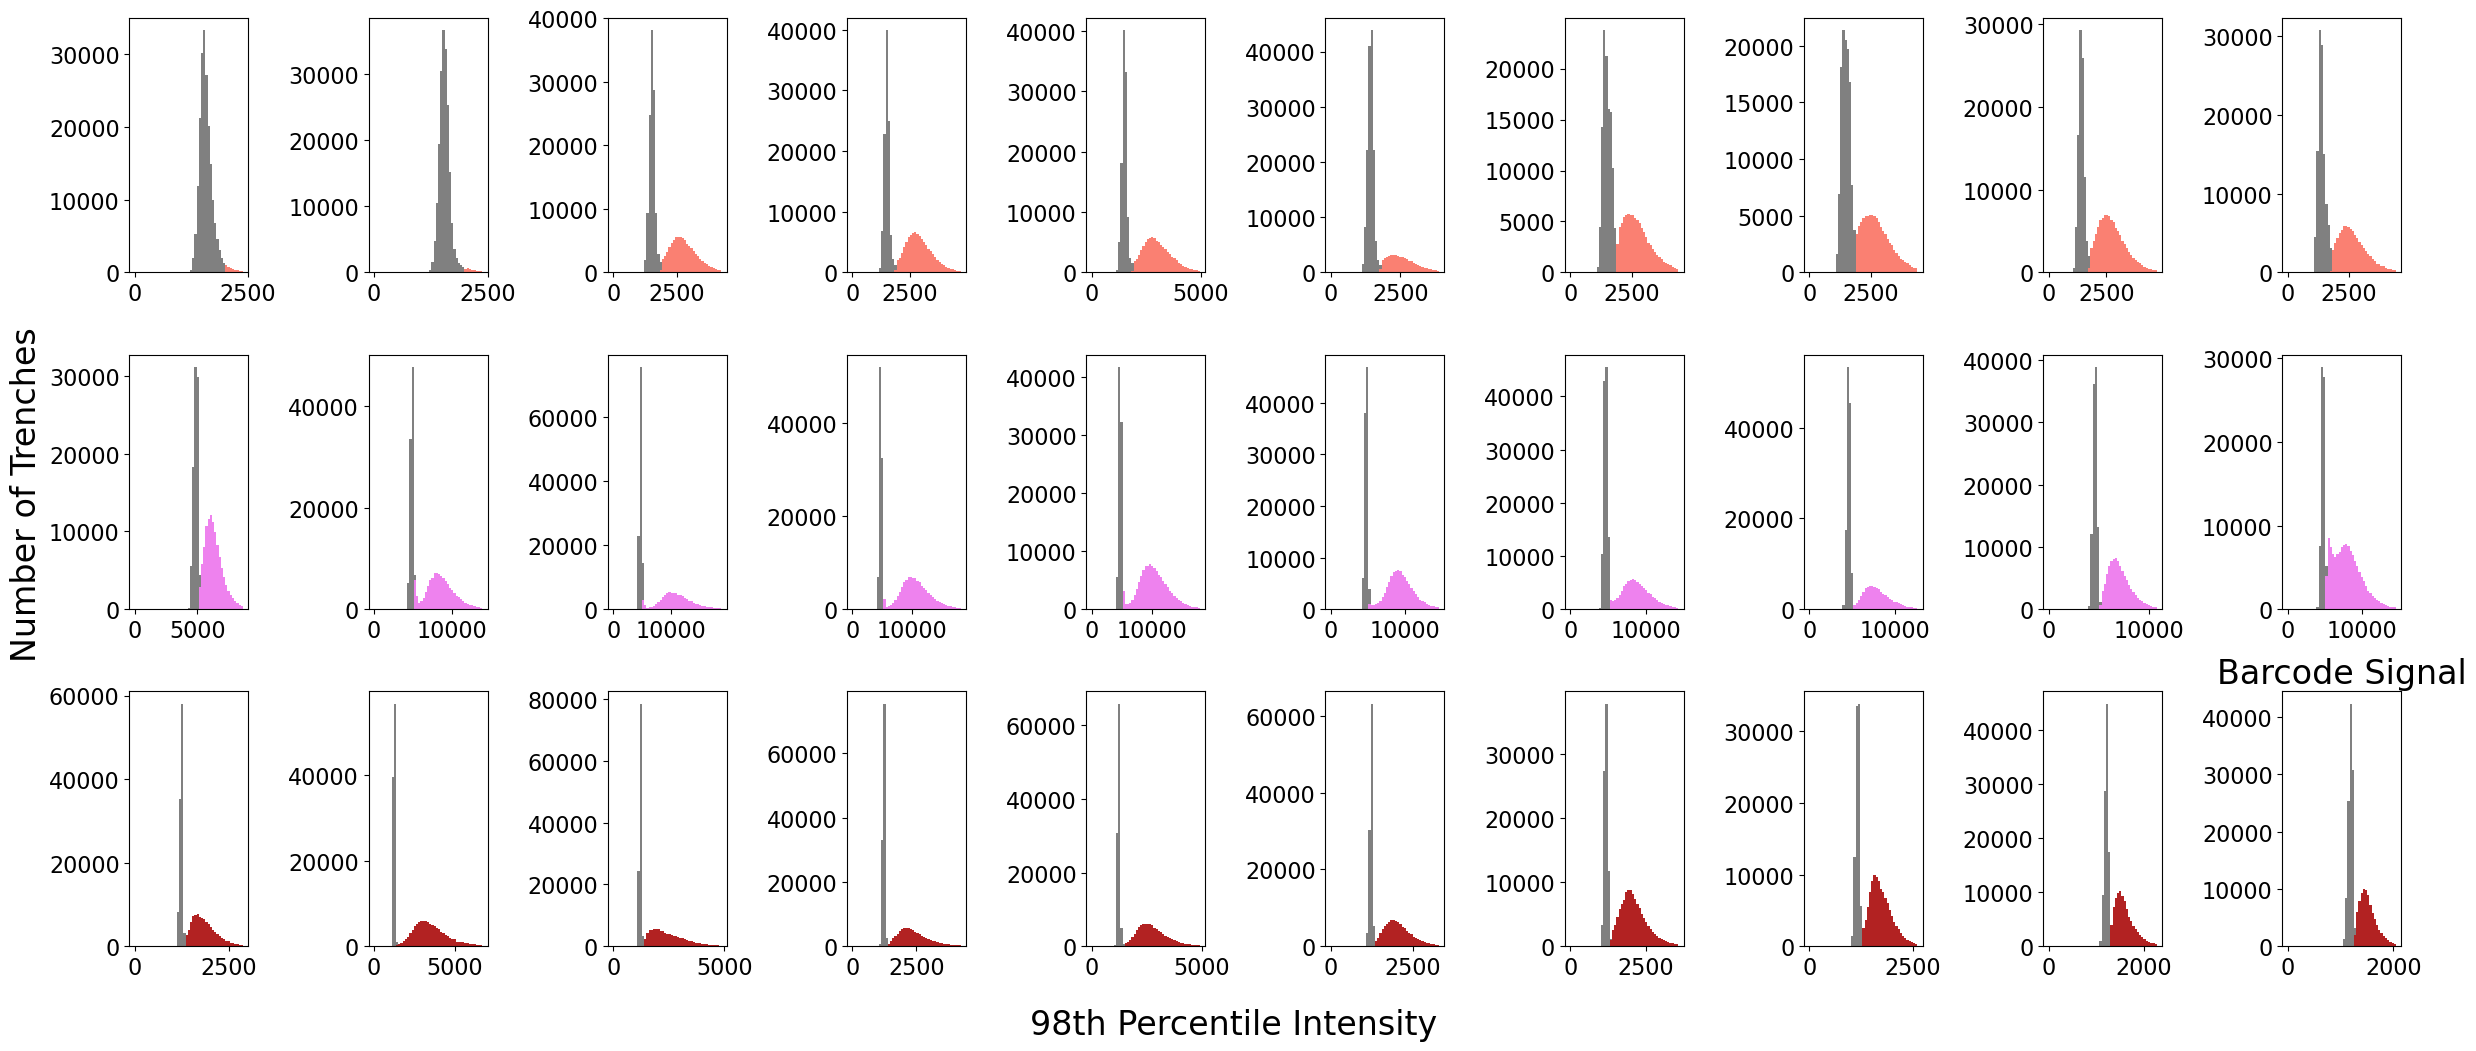

In [17]:
fish_test.export_bit_thresholds()

In [ ]:
print(1)

In [ ]:
fish_test.nanoporedfpath

In [32]:
fish_test.nanoporedfpath = "/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/lLAG8_final_df_fiducials.tsv"

In [ ]:
dask_controller.shutdown()

In [18]:
headpath

'/home/lag36/scratch/lag36/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/Barcodes/'

In [19]:
fish_test.output_barcode_df(dask_controller,headpath+'/2025-05-02_barcode_output_df_fiducials_hamming-2_rm-0-1.hdf5')

Getting Barcode df...


/home/lag36/gutiloluis/TrenchRipper/trenchripper/marlin.py:732: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  barcodes = trench_group.apply(lambda x: list(itertools.chain.from_iterable([x[channel].tolist()\
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 389.26 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


Getting Nanopore df...
Merging...


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/array/routines.py:443: PerformanceWarning: Increasing number of chunks by factor of 41
  out = blockwise(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/array/routines.py:443: PerformanceWarning: Increasing number of chunks by factor of 41
  out = blockwise(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 27.20 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 27.20 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/zarr/creation.py:295: UserWarning: ignoring keyword argument 'inline_array'
  warn(

In [21]:
dask_controller.shutdown()

Done.


2025-05-02 14:17:57,535 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [20]:

import pandas as pd
df = pd.read_hdf(headpath+'/2025-05-02_barcode_output_df_fiducials_hamming-2_rm-0-1.hdf5')
df


,trenchid,Barcode Signal,Barcode,consensus,reference,alignmentstart,cigar,subsample,barcode depth,closest_match,...,locus_tag,offset,Gene,sgRNA Sequence,Target Sequence,Category,Predicted_Efficacy,TargetID,barcode,barcodeid
0,383,"[0.0, 0.0, 1586.02, 1605.1, 3509.4399999999996...",000010010100101100010000101100,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,286.0,2,...,BSU_tRNA_7,21.0,trnSL-Ser1,TCAAGACCGATCCCTTCAGA,GCTGAAGGGATCGGTCTTGA,tRNA,0.242480,2411.0,000000001000101110010011010000,298364
1,411,"[0.0, 0.0, 1846.6799999999994, 1835.5599999999...",000011000100010000011010111001,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,378M2D213M2D496M,NaN,341.0,2,...,BSU_15500,616.0,pyrC,TGAACCGATTCACACACATA,TCTGTGTGTGAATCGGTTCA,auxotroph,0.296615,2116.0,000010000110110011000010010101,204690
2,599,"[0.0, 0.0, 1458.0, 3040.02, 1514.0, 1384.08, 2...",000100111111101100110100001101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,136.0,4,...,BSU_01270,142.0,rplX,CCTTGAGGGTTTGCTTGAGT,ACTCAAGCTAACCCTCAAGG,essential,0.841505,302.0,001101011000001100110011111101,388409
3,704,"[0.0, 0.0, 2804.08, 3235.0, 3541.3599999999997...",001110101111011110111011110100,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,1368.0,2,...,BSU_34870,593.0,hisF,TCCCGAAGCGATAACAGGTA,TCCCTGTTATCGCTTCGGGA,auxotroph,0.374373,2344.0,001110110111101111101001111100,400432
4,708,"[0.0, 0.0, 2877.14, 1543.02, 3884.04, 1443.1, ...",001010110011111100101001111011,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,71.0,3,...,BSU_22630,451.0,trpA,TTCAAACGGCTTTCGCTTAT,ACAAGCGAAAGCCGTTTGAA,auxotroph,0.326405,2191.0,001110101101101111110010001011,185459
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475124,530296,"[0.0, 0.0, 1611.02, 2919.24, 1611.02, 1566.0, ...",000100011101011110111111110111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,896M1I195M,NaN,89.0,3,...,BSU_21870,230.0,ilvD,GAAGCCATCATCTACCCCAA,TTGGGGTAGATGATGGCATC,auxotroph,0.893313,2164.0,000111010111101101011001111111,40954
475125,530585,"[0.0, 0.0, 1457.08, 2053.02, 1396.02, 1341.04,...",000100000000000001010100100000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,188.0,3,...,BSU_33900,100.0,eno,CTCCGCTTGGCACTAATGCG,CGCATTAGTGCCAAGCGGAG,essential,1.000000,1716.0,000011010000000010000100001100,315610
475126,530648,"[0.0, 0.0, 2551.08, 2347.16, 1419.1, 1368.0, 1...",001100010000000000010100010100,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,205.0,4,...,BSU_32240,320.0,thrB,TAATTCATAAGCCAGTTCAA,TTGAACTGGCTGATGAATTA,auxotroph,0.679973,2311.0,000001110000100001010001001100,307894
475127,530653,"[0.0, 0.0, 4932.08, 1746.2199999999998, 1914.0...",001010010010101111111101100111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,77.0,4,...,BSU_01440,340.0,rplQ,AACAATTCGATAATTGCCAT,ATGGCAATTATCGAATTGGT,essential,0.734019,395.0,001011101001001110011101001111,70638


In [ ]:
import pandas as pd
df = pd.read_hdf(headpath+'/barcode_output_df_fiducials_hamming-0_rm-1-28.hdf5')
df


,trenchid,Barcode Signal,Barcode,consensus,reference,alignmentstart,cigar,subsample,barcode depth,closest_match,...,locus_tag,offset,Gene,sgRNA Sequence,Target Sequence,Category,Predicted_Efficacy,TargetID,barcode,barcodeid
0,3113,"[6210.599999999999, 0.0, 6723.799999999999, 59...",101111111011000110111110100100,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,4523.0,3,...,BSU_15680,369.0,gmk,CAGAAACGCTTGGAGGCGCA,TGCGCCTCCAAGCCTTTCTG,essential,0.833878,765.0,101111110100111100111101100100,85093
1,3242,"[2608.0, 0.0, 7769.08, 2427.18, 2406.02, 2327....",001000000100010001110001100101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,966.0,4,...,BSU_33910,292.0,pgm,TCCCGTTGCTGATCGCGTCA,TGACGCGATCAGCAACGCGA,essential,0.818116,1728.0,000000101101001000000001011101,1148
2,3445,"[4139.0599999999995, 0.0, 2259.08, 3891.2, 411...",100110101001010110110011101101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,522.0,3,...,NaN,NaN,NaN,AGAGCATAATCCGGATATCC,GGATATCCGGATTATGCTCT,control,NaN,2788.0,101101010101101000100111101101,80266
3,4037,"[8144.12, 0.0, 2936.02, 2749.0, 2744.02, 8915....",100001000110111111111001000000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,3641.0,3,...,BSU_23380,97.0,lysA,GCCACATCATATACGTAAAC,CTTTACGTATATGATGTGGC,auxotroph,0.083748,2226.0,101110001111011110000000011000,112925
4,4290,"[2419.1, 0.0, 2408.02, 3955.06, 2349.02, 2327....",000100000111110011110010011100,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,831M1I260M,NaN,536.0,4,...,BSU_29470,6.0,ackA,CGCGTTAATTGCAATAATTT,AAATTATTGCAATTAACGCA,essential,0.866134,1577.0,000111011111001001000111010000,11836
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
269480,1336701,"[8065.04, 0.0, 2401.06, 2287.0, 2293.0, 2264.0...",100000000110101000101110100000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,511M1D579M,NaN,855.0,4,...,BSU_11010,1146.0,yitJ,TACGGTCACGGCACGTAATT,TATTACGTGCCGTGACCGTA,auxotroph,0.388514,2059.0,100010000110000110001100010100,88590
269481,1337427,"[2162.0, 0.0, 6547.02, 6186.48, 2071.02, 2060....",001100010101101110010101101001,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,247.0,3,...,BSU_28290,386.0,ilvC,CAACTGTCCCGGGCCTTTAG,CTAAAGGCCCGGGACACTTG,auxotroph,0.809468,2258.0,001101110010001010011010011101,23605
269482,1338988,"[2354.02, 0.0, 2363.0, 2208.08, 2303.0, 2216.0...",000000011110010001111100001101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,562.0,2,...,BSU_00020,217.0,dnaN,GCCTGTAAAACGACGCTTCC,GGAAGCATCGTTTTACAGGC,essential,0.575392,12.0,000010001101001100011011110001,3328
269483,1339439,"[2267.0, 0.0, 2305.02, 2176.02, 10051.27999999...",000010001010001100101100110101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,2881.0,4,...,BSU_16750,402.0,asd,GTTCAAGTGCCGCAACAATT,AATGGTTGCGGCACTTGAAC,essential,0.469439,991.0,001010000100100111001001100101,16837


In [19]:
dask_controller.shutdown()

Done.


In [ ]:
import pandas as pd
df = pd.read_hdf('/home/lag36/scratch/lag36/2024-10-31_lLAG8_MBM_Run-2/Barcodes/barcode_output_df_fiducials.hdf5')
df

In [ ]:
df.loc[df['Category']=='fiducial', :]

In [ ]:
df_2_1.loc[df_2_1['Category']=='fiducial', :]

In [ ]:
dask_controller.shutdown()

In [ ]:
import pandas as pd
df = pd.read_hdf('/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Barcodes/barcode_output_df_alternative.hdf5')
df